# 1. Project Title

# Student Performance Analysis and Prediction System

**Minor Project - AI/ML with Python Training Program (Sept 2026 Batch)**

| | |
|---|---|
| **Student name** | `Nikita Jadhav` |
| **Enrollment / roll number** | `AIML-A6/SEP- 11807` |
| **College / institution** | `PDEA College of Engineering` |
| **Mentor / trainer** | `Pratham Saxena` |
| **Submission date** | `09 November 2026` |

*Algorithm: Linear Regression (scikit-learn). Libraries: Python, NumPy, Pandas, Matplotlib, Seaborn, scikit-learn.*

# 2. Introduction

Examination results are influenced by many things: how much a student studies, how regularly they attend class, and how well they did before. Teachers and institutions would like to understand **which of these factors are associated with final marks** and, if possible, **estimate expected marks early enough to offer support**.

This notebook builds a complete, beginner-friendly data-science workflow on a public student-performance dataset:

1. load and inspect the data,
2. clean it (missing values, duplicates, impossible values),
3. explore it with statistics and charts,
4. train a **Linear Regression** model to predict final examination marks,
5. evaluate it honestly on unseen data, and
6. interpret what the results do - and do not - tell us.

# 3. Problem Statement

Develop a Python-based Machine Learning system that analyses students' academic performance, identifies factors associated with their results, and predicts expected examination marks using historical student data.

The system must analyse the relationships between **study hours, attendance, previous examination marks and final examination scores**, and use **Linear Regression** to predict **final examination marks**.

# 4. Project Objectives

1. Load a student performance dataset with Pandas and NumPy and inspect it.
2. Handle missing values, duplicate records and invalid values without discarding useful information.
3. Engineer simple features that make academic patterns easier to see.
4. Compute descriptive statistics (mean, median, standard deviation, minimum, maximum).
5. Produce bar charts, histograms, scatter plots, box plots and a correlation heatmap - and **interpret every one**.
6. Train a Linear Regression model (target: `Exam_Score`; inputs: study hours, attendance, previous marks).
7. Evaluate it with **MAE, RMSE and R²**, plus cross-validation, and verify there is **no data leakage**.
8. Compare actual and predicted marks and identify students who may benefit from extra support, *fairly and transparently*.
9. Provide a validated prediction function.
10. Document findings, limitations and future improvements.

# 5. Importing Required Libraries

All libraries below are listed in `requirements.txt`. The cell also fixes one random seed (`RANDOM_STATE = 42`) so every run gives identical numbers, and creates the folders where charts and result files are saved.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats                      # only for a provenance check and a simple line fit

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Hide two harmless warnings raised *inside* Seaborn when it is used with very new Matplotlib versions
warnings.filterwarnings("ignore", message="vert: bool was deprecated")
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)

# ---- reproducibility and settings ------------------------------------------------
RANDOM_STATE = 42          # same split and same CV folds on every run
TEST_SIZE = 0.20           # 80 % train / 20 % test
CV_FOLDS = 5

# ---- project paths (works from the notebooks/ folder or from the project root) ----
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_PATH = PROJECT_ROOT / "data" / "student_performance_dataset.csv"
VIZ_DIR = PROJECT_ROOT / "outputs" / "visualizations"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "evaluation_results"
VIZ_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ---- consistent chart style --------------------------------------------------------
BLUE, ACCENT, GREY = "#2f6690", "#d1495b", "#6b7280"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e5e7eb",
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


def save_and_show(fig, filename):
    # Save a figure into outputs/visualizations/ and display it in the notebook.
    fig.tight_layout()
    fig.savefig(VIZ_DIR / filename, bbox_inches="tight", facecolor="white")
    plt.show()

print("Libraries imported. Project root:", PROJECT_ROOT)
print("Pandas", pd.__version__, "| NumPy", np.__version__, "| Seaborn", sns.__version__)

Libraries imported. Project root: /home/claude/Student_Performance_Analysis
Pandas 3.0.5 | NumPy 2.5.3 | Seaborn 0.13.2


# 6. Dataset Collection and Source

**Dataset used:** *Student Performance Factors* (`StudentPerformanceFactors.csv`), a public CSV dataset published on Kaggle by **lainguyn123**.

- Kaggle page: <https://www.kaggle.com/datasets/lainguyn123/student-performance-factors>
- Licence: stated as **CC0: Public Domain** in the README of the public GitHub repository from which this copy of the CSV was obtained (<https://github.com/symemi115/student-performance-factors>, file `Data/Raw/StudentPerformanceFactors.csv`). *The licence could not be re-checked directly on the Kaggle page from the development environment - please confirm it on the Kaggle page before publishing.*
- The CSV in `data/student_performance_dataset.csv` is the **original, unmodified file** (renamed only; 6,607 rows, 20 columns). All cleaning happens inside this notebook; the original is never overwritten.

**Why this dataset?** It contains every feature the project needs: `Hours_Studied` (weekly study hours), `Attendance` (percentage), `Previous_Scores` (marks out of 100) and `Exam_Score` (final marks), plus extra context columns.

**Important note on provenance.** The publisher does not document how the records were collected, and this notebook does not claim they are verified real-world student records. Section 14 shows that the numeric columns are unusually regular (for example `Hours_Studied` is almost perfectly bell-shaped). Treat the findings as an analysis of *this dataset*, not as proven facts about all students.

# 7. Loading the Dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Put 'student_performance_dataset.csv' in the data/ folder "
        "(in Google Colab: upload the project folder or the CSV first)."
    )

raw_df = pd.read_csv(DATA_PATH)          # untouched original; we only ever work on copies of it
print("Dataset loaded from:", DATA_PATH.relative_to(PROJECT_ROOT))
print("Rows, columns      :", raw_df.shape)

Dataset loaded from: data/student_performance_dataset.csv
Rows, columns      : (6607, 20)


# 8. Initial Dataset Inspection

We look at the first records, the shape, the column names, the data types and the missing values *before* changing anything.

In [3]:
print("First 5 records")
raw_df.head()

First 5 records


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
print("Shape (rows, columns):", raw_df.shape)
print("\nColumn names:")
print(list(raw_df.columns))
print("\nData types:")
print(raw_df.dtypes.to_string())

Shape (rows, columns): (6607, 20)

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Data types:
Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learni

In [5]:
# Missing values per column (only columns that have any are shown) and duplicate count
missing_raw = raw_df.isna().sum()
print("Missing values per column (columns with at least one missing value):")
print(missing_raw[missing_raw > 0].to_string())
print("\nTotal missing cells :", int(missing_raw.sum()))
print("Duplicate rows      :", int(raw_df.duplicated().sum()))

Missing values per column (columns with at least one missing value):
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67

Total missing cells : 235
Duplicate rows      : 0


**What we learn.** The dataset has 6,607 students and 20 columns. Four columns are exactly what the project needs: `Hours_Studied`, `Attendance`, `Previous_Scores` and `Exam_Score` (all stored as integers). Three *categorical* columns have missing values (`Teacher_Quality` 78, `Parental_Education_Level` 90, `Distance_from_Home` 67). There are no duplicate rows. None of the four key columns has a missing value.

# 9. Data Cleaning

Cleaning means making sure every value is *possible* before we analyse it. We work on a copy called `df` so the original stays untouched.

**Checks performed**
1. Are the categorical labels consistent (no typos or mixed spellings)?
2. Are the numeric values possible? Marks must be between 0 and 100, attendance between 0 and 100 %, and weekly study hours between 0 and 168 (the number of hours in a week).
3. Are there statistical outliers? (Identified, but *not* automatically deleted.)

In [6]:
df = raw_df.copy()

# 1) Label consistency: list the distinct values of every non-numeric column
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()
for column in categorical_columns:
    print(f"{column:28s}", sorted(df[column].dropna().unique()))

Parental_Involvement         ['High', 'Low', 'Medium']
Access_to_Resources          ['High', 'Low', 'Medium']
Extracurricular_Activities   ['No', 'Yes']
Motivation_Level             ['High', 'Low', 'Medium']
Internet_Access              ['No', 'Yes']
Family_Income                ['High', 'Low', 'Medium']
Teacher_Quality              ['High', 'Low', 'Medium']
School_Type                  ['Private', 'Public']
Peer_Influence               ['Negative', 'Neutral', 'Positive']
Learning_Disabilities        ['No', 'Yes']
Parental_Education_Level     ['College', 'High School', 'Postgraduate']
Distance_from_Home           ['Far', 'Moderate', 'Near']
Gender                       ['Female', 'Male']


In [7]:
# 2) Impossible values (limits come from the meaning of each column)
LIMITS = {
    "Hours_Studied":   (0, 168),   # hours in a week
    "Attendance":      (0, 100),   # percent
    "Previous_Scores": (0, 100),   # marks out of 100
    "Exam_Score":      (0, 100),   # marks out of 100
}
invalid_mask = pd.Series(False, index=df.index)
for column, (low, high) in LIMITS.items():
    bad = (df[column] < low) | (df[column] > high)
    print(f"{column:16s} allowed {low}-{high} -> invalid values: {int(bad.sum())}")
    invalid_mask |= bad

print("\nRows with impossible values:", int(invalid_mask.sum()))
df.loc[invalid_mask, ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]]

Hours_Studied    allowed 0-168 -> invalid values: 0
Attendance       allowed 0-100 -> invalid values: 0
Previous_Scores  allowed 0-100 -> invalid values: 0
Exam_Score       allowed 0-100 -> invalid values: 1

Rows with impossible values: 1


,Hours_Studied,Attendance,Previous_Scores,Exam_Score
1525,27,98,93,101


**Decision.** One student has `Exam_Score = 101`, which is impossible for an exam marked out of 100 - the *target value itself* is wrong, so the row cannot be used for training or evaluation. Only this one row (0.015 % of the data) is removed. Every other value is within the possible range.

In [8]:
rows_before_invalid = len(df)
invalid_row_index = [int(i) for i in df.index[invalid_mask]]
df = df.loc[~invalid_mask].copy()
print(f"Rows before: {rows_before_invalid}  | removed: {int(invalid_mask.sum())}  | rows now: {len(df)}")

Rows before: 6607  | removed: 1  | rows now: 6606


In [9]:
# 3) Outlier IDENTIFICATION with the 1.5 x IQR rule (identification only - nothing is deleted here)
def iqr_outlier_summary(frame, columns):
    rows = []
    for column in columns:
        q1, q3 = frame[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((frame[column] < lower) | (frame[column] > upper)).sum())
        rows.append({"column": column, "lower_bound": round(float(lower), 2), "upper_bound": round(float(upper), 2),
                     "outlier_count": n_out, "outlier_percent": round(100 * n_out / len(frame), 2)})
    return pd.DataFrame(rows)

outlier_table = iqr_outlier_summary(df, ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"])
outlier_table.to_csv(RESULTS_DIR / "outlier_summary.csv", index=False)
outlier_table

,column,lower_bound,upper_bound,outlier_count,outlier_percent
0,Hours_Studied,4.0,36.0,43,0.65
1,Attendance,40.0,120.0,0,0.00
2,Previous_Scores,25.5,125.5,0,0.00
3,Exam_Score,59.0,75.0,103,1.56


**Decision on outliers.** `Hours_Studied` has 43 values above 36 hours and `Exam_Score` has 103 values outside 59-75 marks (1.56 %). These are *possible* values - a student who studies 44 hours a week, or scores 95, is unusual but not impossible. They are real academic variation, so they are **kept**. Deleting them would remove exactly the high and low achievers we want to learn about. We will, however, remember that they affect error metrics (see Sections 28-32).

# 10. Missing Value Handling

Only three *categorical* columns contain missing values. None of them is used as a model input, and none is a key academic column. A good way to treat missing categories is to keep the student and label the gap explicitly as `"Unknown"`:

- no student record (and no valid study hours / marks) is thrown away,
- no statistic is calculated from the data, so **nothing can leak from the test set**,
- "not recorded" is kept visible instead of being silently guessed.

(If numeric model inputs had missing values, a median imputer *inside the scikit-learn Pipeline* would handle them - see Section 24.)

Missing values before: {'Teacher_Quality': 78, 'Parental_Education_Level': 90, 'Distance_from_Home': 67}
Missing cells after  : 0


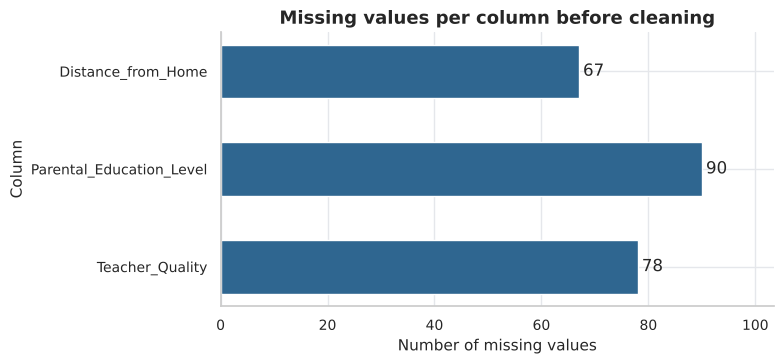

In [10]:
columns_with_missing = ["Teacher_Quality", "Parental_Education_Level", "Distance_from_Home"]
missing_before = df[columns_with_missing].isna().sum()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(missing_before.index, missing_before.values, color=BLUE, height=0.55)
ax.bar_label(bars, padding=3)
ax.set_title("Missing values per column before cleaning")
ax.set_xlabel("Number of missing values")
ax.set_ylabel("Column")
ax.set_xlim(0, missing_before.max() * 1.15)
save_and_show(fig, "01_missing_values_before_cleaning.png")

for column in columns_with_missing:
    df[column] = df[column].fillna("Unknown")

print("Missing values before:", missing_before.to_dict())
print("Missing cells after  :", int(df.isna().sum().sum()))

# 11. Duplicate Record Handling

An exact duplicate row would count the same student twice and could put identical records into both the training and the test set (a form of leakage). We check and remove exact duplicates.

In [11]:
duplicates_found = int(df.duplicated().sum())
print("Exact duplicate rows found:", duplicates_found)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after duplicate handling:", len(df))

# Save the cleaning report (used later by the PDF report)
cleaning_report = {
    "rows_raw": int(len(raw_df)),
    "missing_values_before": {k: int(v) for k, v in missing_before.items() if v > 0},
    "missing_values_after": int(df.isna().sum().sum()),
    "duplicate_rows_found": duplicates_found,
    "invalid_rows_found": len(invalid_row_index),
    "invalid_row_index": invalid_row_index,
    "rows_clean": int(len(df)),
}
(RESULTS_DIR / "data_cleaning_report.json").write_text(json.dumps(cleaning_report, indent=2))
pd.Series(cleaning_report, name="value").to_frame()

Exact duplicate rows found: 0
Rows after duplicate handling: 6606


,value
rows_raw,6607
missing_values_before,"{'Teacher_Quality': 78, 'Parental_Education_Le..."
missing_values_after,0
duplicate_rows_found,0
invalid_rows_found,1
invalid_row_index,[1525]
rows_clean,6606


**Result of cleaning.** The dataset contained no duplicates. After filling 235 missing category cells with `"Unknown"` and removing one impossible row, the cleaned dataset has **6,606 rows and 20 columns, with no missing values**.

# 12. Feature Engineering

We add a few simple, readable columns that make academic patterns easier to see in charts.

| New column | How it is made | Used for |
|---|---|---|
| `Study_Hours_Band` | fixed bins of `Hours_Studied` (1-10, 11-20, 21-30, 31+ h) | bar / box charts |
| `Attendance_Band` | fixed bins of `Attendance` (<=70, 71-80, 81-90, 91-100 %) | bar / box charts |
| `Previous_Score_Band` | fixed bins of `Previous_Scores` | bar charts |
| `Score_Change` | `Exam_Score - Previous_Scores` | analysis only |
| `Performance_Level` | fixed bins of `Exam_Score` | analysis only |

**Leakage warning.** `Score_Change` and `Performance_Level` are calculated from the *target* (`Exam_Score`). They are used **only for description** and are never given to the model as inputs - a model that sees them would effectively be given the answer. The bin edges are fixed human-readable numbers, not statistics learned from the data, so the bands cannot leak information between training and test data either.

In [12]:
df["Study_Hours_Band"] = pd.cut(df["Hours_Studied"], bins=[0, 10, 20, 30, np.inf],
                                labels=["1-10 h", "11-20 h", "21-30 h", "31+ h"])
df["Attendance_Band"] = pd.cut(df["Attendance"], bins=[0, 70, 80, 90, 100],
                               labels=["<=70 %", "71-80 %", "81-90 %", "91-100 %"])
df["Previous_Score_Band"] = pd.cut(df["Previous_Scores"], bins=[0, 60, 70, 80, 90, 100],
                                   labels=["<=60", "61-70", "71-80", "81-90", "91-100"])
df["Score_Change"] = df["Exam_Score"] - df["Previous_Scores"]            # analysis only (uses the target)
df["Performance_Level"] = pd.cut(df["Exam_Score"], bins=[0, 60, 70, 80, 100],
                                 labels=["Below 60", "60-70", "70-80", "Above 80"])   # analysis only

engineered = ["Study_Hours_Band", "Attendance_Band", "Previous_Score_Band", "Score_Change", "Performance_Level"]
print("Records in every new band (should add up to", len(df), "):")
for column in ["Study_Hours_Band", "Attendance_Band", "Previous_Score_Band", "Performance_Level"]:
    print(f"  {column:20s}", df[column].value_counts(sort=False).to_dict(), "| unassigned:", int(df[column].isna().sum()))
df[["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"] + engineered].head(8)

Records in every new band (should add up to 6606 ):
  Study_Hours_Band     {'1-10 h': 365, '11-20 h': 3179, '21-30 h': 2809, '31+ h': 253} | unassigned: 0
  Attendance_Band      {'<=70 %': 1734, '71-80 %': 1689, '81-90 %': 1594, '91-100 %': 1589} | unassigned: 0
  Previous_Score_Band  {'<=60': 1356, '61-70': 1346, '71-80': 1323, '81-90': 1314, '91-100': 1267} | unassigned: 0
  Performance_Level    {'Below 60': 145, '60-70': 5379, '70-80': 1040, 'Above 80': 42} | unassigned: 0


,Hours_Studied,Attendance,Previous_Scores,Exam_Score,Study_Hours_Band,Attendance_Band,Previous_Score_Band,Score_Change,Performance_Level
0,23,84,73,67,21-30 h,81-90 %,71-80,-6,60-70
1,19,64,59,61,11-20 h,<=70 %,<=60,2,60-70
2,24,98,91,74,21-30 h,91-100 %,91-100,-17,70-80
3,29,89,98,71,21-30 h,81-90 %,91-100,-27,70-80
4,19,92,65,70,11-20 h,91-100 %,61-70,5,60-70
5,19,88,89,71,11-20 h,81-90 %,81-90,-18,70-80
6,29,84,68,67,21-30 h,81-90 %,61-70,-1,60-70
7,25,78,50,66,21-30 h,71-80 %,<=60,16,60-70


# 13. Descriptive Statistics

Mean, median and standard deviation (mandatory), plus minimum, maximum and quartiles, for the four key academic columns.

In [13]:
KEY_COLUMNS = ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
desc = pd.DataFrame({
    "Mean": df[KEY_COLUMNS].mean(),
    "Median": df[KEY_COLUMNS].median(),
    "Std Dev": df[KEY_COLUMNS].std(),
    "Min": df[KEY_COLUMNS].min(),
    "25%": df[KEY_COLUMNS].quantile(0.25),
    "75%": df[KEY_COLUMNS].quantile(0.75),
    "Max": df[KEY_COLUMNS].max(),
    "Skewness": df[KEY_COLUMNS].skew(),
}).round(3)
desc.index.name = "Variable"
desc.to_csv(RESULTS_DIR / "descriptive_statistics.csv")
desc

,Mean,Median,Std Dev,Min,25%,75%,Max,Skewness
Variable,,,,,,,,
Hours_Studied,19.974,20.0,5.990,1,16.0,24.0,44,0.014
Attendance,79.975,80.0,11.546,60,70.0,90.0,100,0.014
Previous_Scores,75.068,75.0,14.399,50,63.0,88.0,100,-0.003
Exam_Score,67.231,67.0,3.869,55,65.0,69.0,100,1.576


In [14]:
# Other numeric columns in the dataset (context only) and the distribution of the target
print("Other numeric columns:")
print(df[["Sleep_Hours", "Tutoring_Sessions", "Physical_Activity"]].agg(["mean", "median", "std", "min", "max"]).round(3).to_string())
print("\nScore_Change (Exam_Score - Previous_Scores): mean = %.2f, median = %.1f, std = %.2f"
      % (df["Score_Change"].mean(), df["Score_Change"].median(), df["Score_Change"].std()))
print("\nStudents per Performance_Level:")
print(df["Performance_Level"].value_counts(sort=False).to_string())

Other numeric columns:
        Sleep_Hours  Tutoring_Sessions  Physical_Activity
mean          7.029              1.493              2.968
median        7.000              1.000              3.000
std           1.468              1.230              1.031
min           4.000              0.000              0.000
max          10.000              8.000              6.000

Score_Change (Exam_Score - Previous_Scores): mean = -7.84, median = -8.0, std = 14.24

Students per Performance_Level:
Performance_Level
Below 60     145
60-70       5379
70-80       1040
Above 80      42


**Reading the table.**

- **Exam_Score**: mean 67.23, median 67, standard deviation 3.87, range 55-100. The scores are tightly bunched (most students are within a few marks of 67) with a *long tail to the right* (skewness 1.58) - a small number of students score far above the rest.
- **Hours_Studied**: mean about 20 hours/week (median 20, SD 5.99). Mean and median are almost identical and the skewness is about 0, so the distribution is symmetric.
- **Attendance**: mean about 80 % (SD 11.55), ranging from 60 % to 100 %. No student in the dataset has attendance below 60 %.
- **Previous_Scores**: mean 75.07, median 75, SD 14.40, ranging from 50 to 100 - much *more spread out* than the final scores.

An important consequence: final marks vary by only about 3.9 marks (one SD), so even a good model can only be expected to be accurate within a few marks.

# 14. Exploratory Data Analysis

Exploratory Data Analysis (EDA) asks: *what does the data look like, and how do the academic variables relate to each other?* We use bar charts, histograms, scatter plots, box plots and a correlation heatmap, and we interpret each chart.

**Reminder.** Correlation measures how two variables move together. It does **not** prove that one causes the other.

First, a short check of how regular the numeric columns are (provenance note from Section 6).

In [15]:
# Provenance note: how 'regular' are the distributions?  (descriptive check, not used by the model)
for column, low, high in [("Attendance", 60, 100), ("Previous_Scores", 50, 100)]:
    counts = df[column].value_counts().reindex(range(low, high + 1), fill_value=0).to_numpy()
    chi2 = stats.chisquare(counts)
    print(f"{column:16s} min={df[column].min()}, max={df[column].max()}, std={df[column].std():.2f}  "
          f"(std of a perfectly flat {low}-{high} distribution = {(high - low) / np.sqrt(12):.2f}); "
          f"chi-square test for exactly equal counts: p = {chi2.pvalue:.1e}")
print(f"Hours_Studied    skewness = {df['Hours_Studied'].skew():.3f}, excess kurtosis = {df['Hours_Studied'].kurt():.3f} "
      "(both ~0 for a perfect bell curve)")

Attendance       min=60, max=100, std=11.55  (std of a perfectly flat 60-100 distribution = 11.55); chi-square test for exactly equal counts: p = 2.4e-08
Previous_Scores  min=50, max=100, std=14.40  (std of a perfectly flat 50-100 distribution = 14.43); chi-square test for exactly equal counts: p = 1.1e-05
Hours_Studied    skewness = 0.014, excess kurtosis = 0.018 (both ~0 for a perfect bell curve)


**Provenance note.** `Attendance` and `Previous_Scores` have standard deviations almost identical to those of perfectly flat (uniform) distributions, and `Hours_Studied` is almost perfectly bell-shaped. The chi-square tests show the counts are *not exactly* equal, so this is not proof of anything - but the columns are more regular than typical real-world records usually are. Because the publisher does not describe how the data were collected, we treat the dataset as a **public teaching dataset** and keep our conclusions limited to patterns *in this data*.

# 15. Bar Charts

Bar charts compare the **average final score** across groups. We use the engineered bands from Section 12 and finish with a bar chart comparing how strongly each numeric column is correlated with the final score.

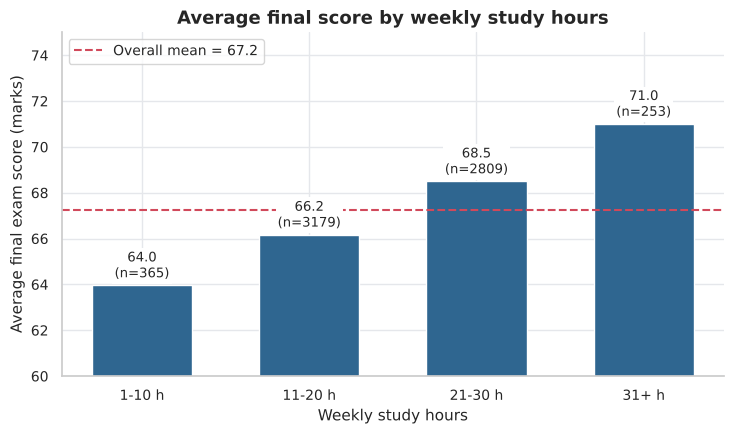

,mean,count
Study_Hours_Band,,
1-10 h,63.97,365
11-20 h,66.18,3179
21-30 h,68.51,2809
31+ h,71.01,253


In [16]:
def bar_mean_score(band_column, xlabel, title, filename):
    # Bar chart of average Exam_Score for each band, with the number of students above each bar.
    summary = df.groupby(band_column, observed=True)["Exam_Score"].agg(["mean", "count"])
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    bars = ax.bar(summary.index.astype(str), summary["mean"], color=BLUE, width=0.6)
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
                f"{row['mean']:.1f}\n(n={int(row['count'])})", ha="center", va="bottom", fontsize=9.5, zorder=5,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
    ax.axhline(df["Exam_Score"].mean(), color=ACCENT, linestyle="--", linewidth=1.5,
               label=f"Overall mean = {df['Exam_Score'].mean():.1f}")
    ax.set_ylim(df["Exam_Score"].min() + 5, summary["mean"].max() + 4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Average final exam score (marks)")
    ax.legend(loc="upper left")
    save_and_show(fig, filename)
    return summary

summary_hours = bar_mean_score("Study_Hours_Band", "Weekly study hours", "Average final score by weekly study hours",
                               "02_bar_mean_score_by_study_hours.png")
summary_hours.round(2)

**Interpretation - study hours.** *What it shows:* the average final score for four groups of weekly study time. *Pattern:* the bars rise steadily - 64.0 marks for 1-10 h, 66.2 for 11-20 h, 68.5 for 21-30 h and 71.0 for 31+ h - about 7 marks between the lowest and highest group. *What it suggests:* in this dataset, students who report more study hours tend to have higher final scores. *Caution:* the vertical axis starts at 60, not 0, to make the differences visible; the two extreme groups are small (365 and 253 students); and the chart cannot show *why* - students who study more may also differ in motivation or other ways.

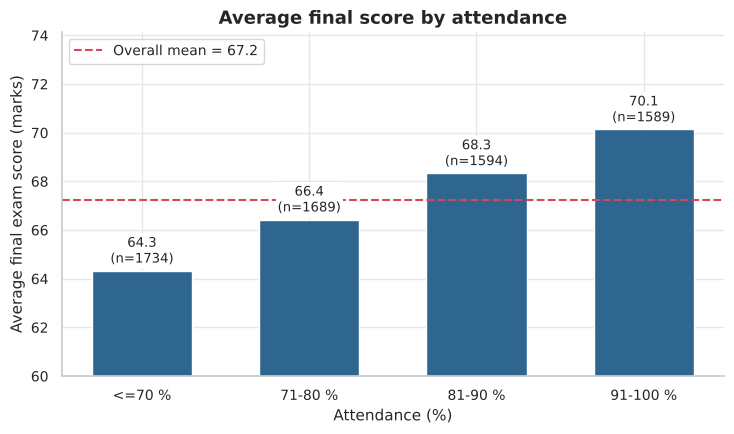

,mean,count
Attendance_Band,,
<=70 %,64.33,1734
71-80 %,66.43,1689
81-90 %,68.34,1594
91-100 %,70.14,1589


In [17]:
summary_attendance = bar_mean_score("Attendance_Band", "Attendance (%)", "Average final score by attendance",
                                    "03_bar_mean_score_by_attendance.png")
summary_attendance.round(2)

**Interpretation - attendance.** *What it shows:* average final score for four attendance groups, each containing roughly 1,600 students. *Pattern:* a clear, almost evenly spaced staircase - 64.3 (<=70 %), 66.4, 68.3 and 70.1 marks (91-100 %), a difference of about 5.8 marks between the lowest and highest group. *What it suggests:* higher attendance is associated with higher final scores, and this relationship looks stronger and more regular than the study-hours one. *Caution:* attendance is associated with, not proven to cause, better marks.

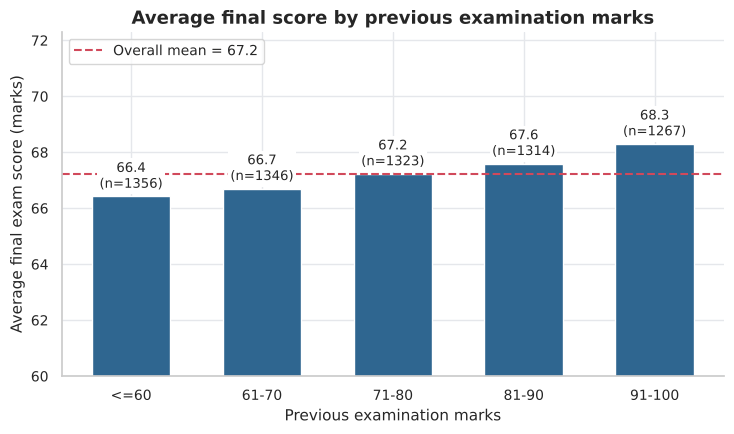

,mean,count
Previous_Score_Band,,
<=60,66.42,1356
61-70,66.70,1346
71-80,67.23,1323
81-90,67.59,1314
91-100,68.30,1267


In [18]:
summary_previous = bar_mean_score("Previous_Score_Band", "Previous examination marks", "Average final score by previous examination marks",
                                  "04_bar_mean_score_by_previous_scores.png")
summary_previous.round(2)

**Interpretation - previous marks.** *What it shows:* average final score for five groups of previous marks. *Pattern:* the bars rise only slightly - from 66.4 (previous marks <=60) to 68.3 (91-100), a difference of just 1.9 marks even though the groups differ by 30-40 marks in previous performance. *What it suggests:* in this dataset, past marks are only weakly related to final marks compared with attendance and study hours. This is a useful, somewhat surprising finding: previous results alone do not "lock in" final results here.

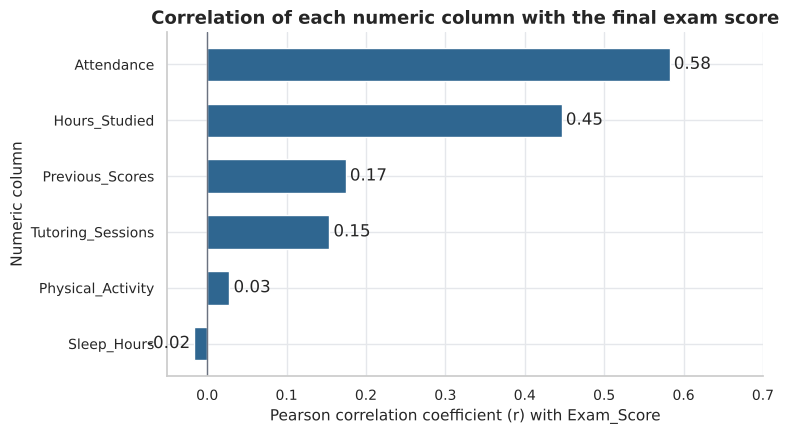

,r with Exam_Score
Attendance,0.582
Hours_Studied,0.447
Previous_Scores,0.174
Tutoring_Sessions,0.154
Physical_Activity,0.028
Sleep_Hours,-0.016


In [19]:
numeric_columns = ["Hours_Studied", "Attendance", "Previous_Scores", "Sleep_Hours", "Tutoring_Sessions", "Physical_Activity"]
corr_with_target = df[numeric_columns].corrwith(df["Exam_Score"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(corr_with_target.index, corr_with_target.values, color=BLUE, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlim(-0.05, 0.7)
ax.set_title("Correlation of each numeric column with the final exam score")
ax.set_xlabel("Pearson correlation coefficient (r) with Exam_Score")
ax.set_ylabel("Numeric column")
save_and_show(fig, "05_bar_correlation_with_exam_score.png")
corr_with_target.round(3).sort_values(ascending=False).to_frame("r with Exam_Score")

**Interpretation - which columns move with the final score?** *What it shows:* Pearson's *r* between each numeric column and `Exam_Score`. *Pattern:* `Attendance` (r = 0.58) is the strongest, then `Hours_Studied` (0.45), then `Previous_Scores` (0.17) and `Tutoring_Sessions` (0.15); `Sleep_Hours` and `Physical_Activity` are close to zero. *What it suggests:* attendance and study hours are the academic variables most strongly associated with final marks in this data. (An r of 0.58 means a moderate positive association; r = 0 would mean no *linear* association.)

# 16. Histograms

Histograms show **how many students fall at each value**. Each plot marks the mean (solid line) and median (dashed line).

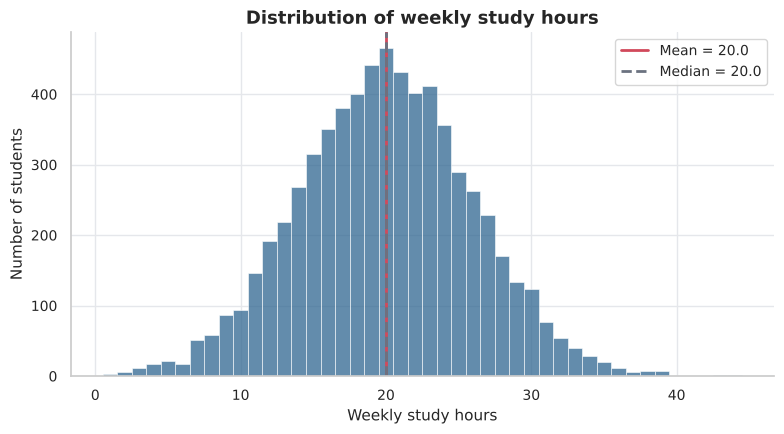

In [20]:
def plot_histogram(column, xlabel, title, filename):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.histplot(df[column], discrete=True, color=BLUE, edgecolor="white", linewidth=0.4, ax=ax)
    ax.axvline(df[column].mean(), color=ACCENT, linewidth=2, label=f"Mean = {df[column].mean():.1f}")
    ax.axvline(df[column].median(), color=GREY, linewidth=2, linestyle="--", label=f"Median = {df[column].median():.1f}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of students")
    ax.legend()
    save_and_show(fig, filename)

plot_histogram("Hours_Studied", "Weekly study hours", "Distribution of weekly study hours", "06_hist_study_hours.png")

**Interpretation - study hours.** A symmetric, bell-shaped distribution centred at about 20 hours per week (mean 19.98, median 20). The middle half of students study between 16 and 24 hours; very few study fewer than 5 or more than 36 hours. Because mean and median coincide there is no skew. The few students at the extremes are the 'outliers' identified earlier - unusual, but kept.

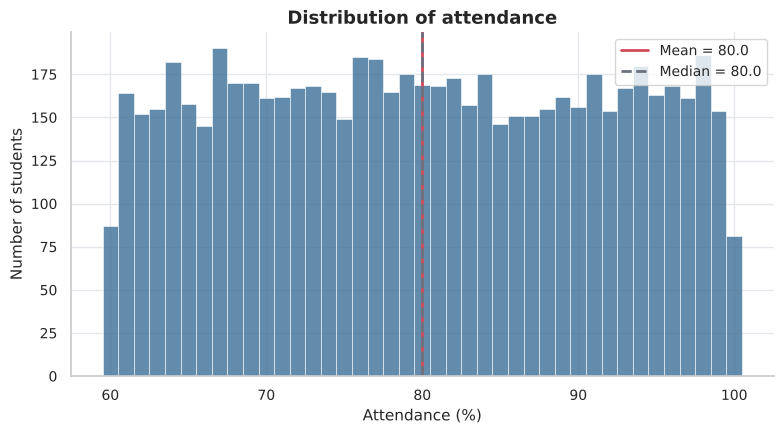

In [21]:
plot_histogram("Attendance", "Attendance (%)", "Distribution of attendance", "07_hist_attendance.png")

**Interpretation - attendance.** Attendance is spread fairly evenly between 60 % and 100 % (mean 79.98, median 80): there is no big peak, and no student is below 60 %. This means the dataset covers students with low-to-excellent attendance in similar numbers, which is helpful for studying its relationship with scores, but it also means we cannot say anything about students attending less than 60 % of classes.

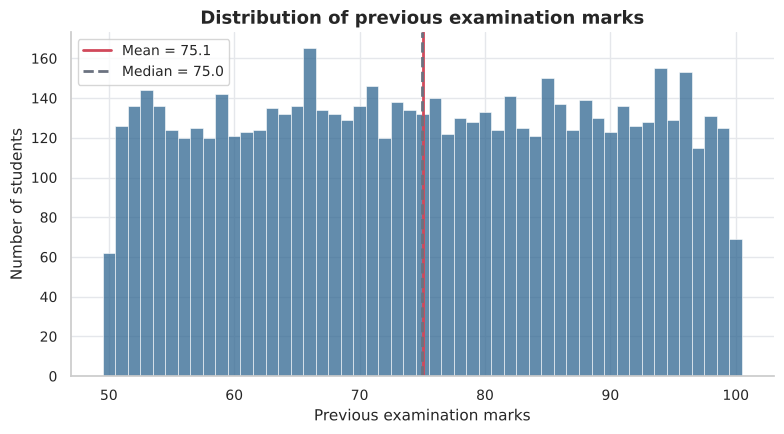

In [22]:
plot_histogram("Previous_Scores", "Previous examination marks", "Distribution of previous examination marks", "08_hist_previous_scores.png")

**Interpretation - previous marks.** Previous marks are also spread roughly evenly from 50 to 100 (mean 75.07, median 75). Compared with the final scores below, the previous marks vary much more from student to student (SD 14.4 vs 3.9).

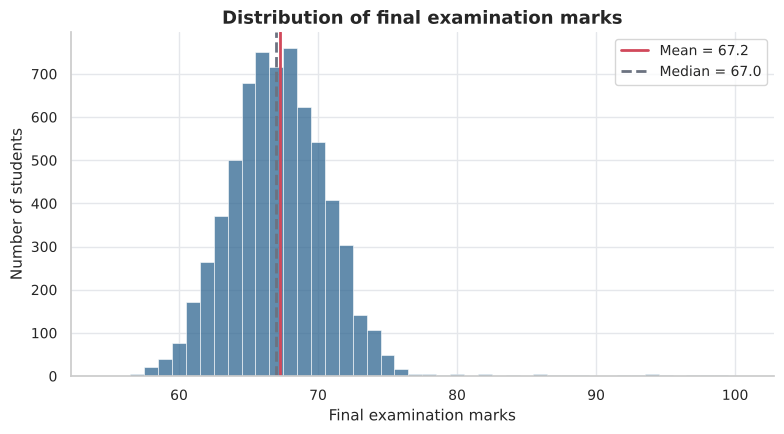

In [23]:
plot_histogram("Exam_Score", "Final examination marks", "Distribution of final examination marks", "09_hist_exam_scores.png")

**Interpretation - final exam scores.** The final marks form a narrow peak around 66-68 (mean 67.23, median 67), with a **long right tail** up to 100 (skewness 1.58). Most students score between 65 and 69; only about 1.6 % score outside the 59-75 range that the box-plot rule treats as normal. This narrow spread matters for modelling: the average student is predicted well by almost any reasonable guess, so a model must beat a very strong "predict the average" baseline (Section 28).

# 17. Scatter Plots

Each dot is one student. The red line is the best straight-line fit through the dots (the same idea as Linear Regression with a single input). Dots are semi-transparent so overlapping students are visible.

Hours_Studied: r = 0.447, slope = 0.2884 marks per unit, R² = 0.199, p-value = 0.0e+00


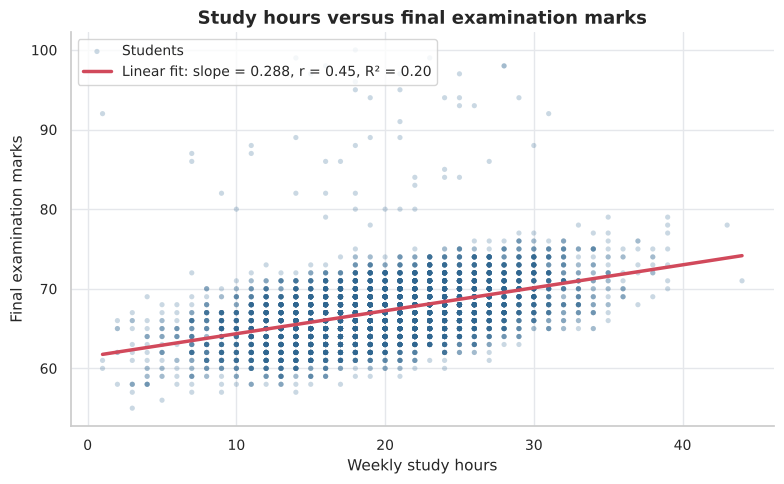

In [24]:
def plot_scatter(column, xlabel, title, filename):
    x, y = df[column], df["Exam_Score"]
    fit = stats.linregress(x, y)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(x, y, s=14, alpha=0.25, color=BLUE, edgecolors="none", label="Students")
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, fit.intercept + fit.slope * xs, color=ACCENT, linewidth=2.5,
            label=f"Linear fit: slope = {fit.slope:.3f}, r = {fit.rvalue:.2f}, R² = {fit.rvalue ** 2:.2f}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Final examination marks")
    ax.legend(loc="upper left")
    save_and_show(fig, filename)
    print(f"{column}: r = {fit.rvalue:.3f}, slope = {fit.slope:.4f} marks per unit, R² = {fit.rvalue ** 2:.3f}, p-value = {fit.pvalue:.1e}")

plot_scatter("Hours_Studied", "Weekly study hours", "Study hours versus final examination marks", "10_scatter_study_hours_vs_exam.png")

**Interpretation - study hours vs final marks.** *What it shows:* one dot per student. *Pattern:* a clear upward drift with a lot of vertical scatter: r = 0.45, slope 0.29 marks per extra weekly study hour, R² = 0.20. *What it suggests:* study hours alone explain about 20 % of the variation in final marks; students who study more tend to score higher, but two students with the same study hours can differ by many marks, so other factors matter. This is a statistical association - it does not prove that adding study hours *causes* higher marks.

Attendance: r = 0.582, slope = 0.1951 marks per unit, R² = 0.339, p-value = 0.0e+00


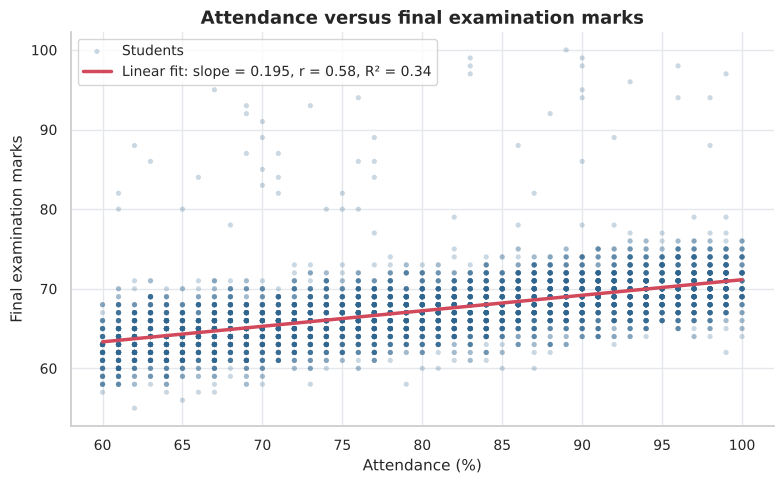

In [25]:
plot_scatter("Attendance", "Attendance (%)", "Attendance versus final examination marks", "11_scatter_attendance_vs_exam.png")

**Interpretation - attendance vs final marks.** *Pattern:* the strongest relationship of the three: r = 0.58, slope 0.195 marks per attendance percentage point, R² = 0.34. *What it suggests:* attendance alone accounts for about a third of the variation in final marks. Going from 60 % to 100 % attendance is associated with roughly 8 extra marks on average (40 × 0.195). Attendance may partly reflect engagement or motivation, so this is an association, not proof that attending class by itself raises marks.

Previous_Scores: r = 0.174, slope = 0.0469 marks per unit, R² = 0.030, p-value = 2.6e-46


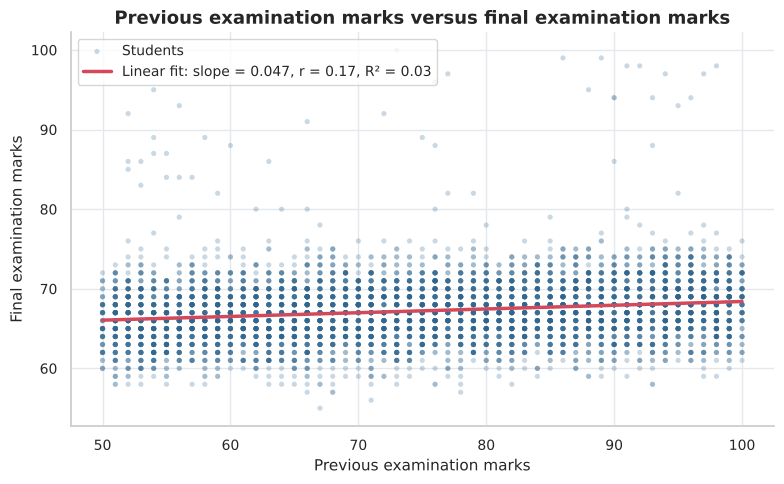

In [26]:
plot_scatter("Previous_Scores", "Previous examination marks", "Previous examination marks versus final examination marks", "12_scatter_previous_vs_exam.png")

**Interpretation - previous marks vs final marks.** *Pattern:* a very shallow upward slope (0.047 marks of final score per previous mark) with r = 0.17 and R² = 0.03 - previous marks alone explain only about 3 % of the variation in final marks. The cloud of dots is almost a horizontal band. *What it suggests:* in this dataset, previous performance is only a weak predictor of the final result; it is still statistically detectable (p-value is tiny because there are 6,606 students) but practically small.

# 18. Box Plots

A box plot shows the median (middle line), the middle 50 % of students (the box) and potential outliers (dots beyond the whiskers, which extend 1.5 × IQR).

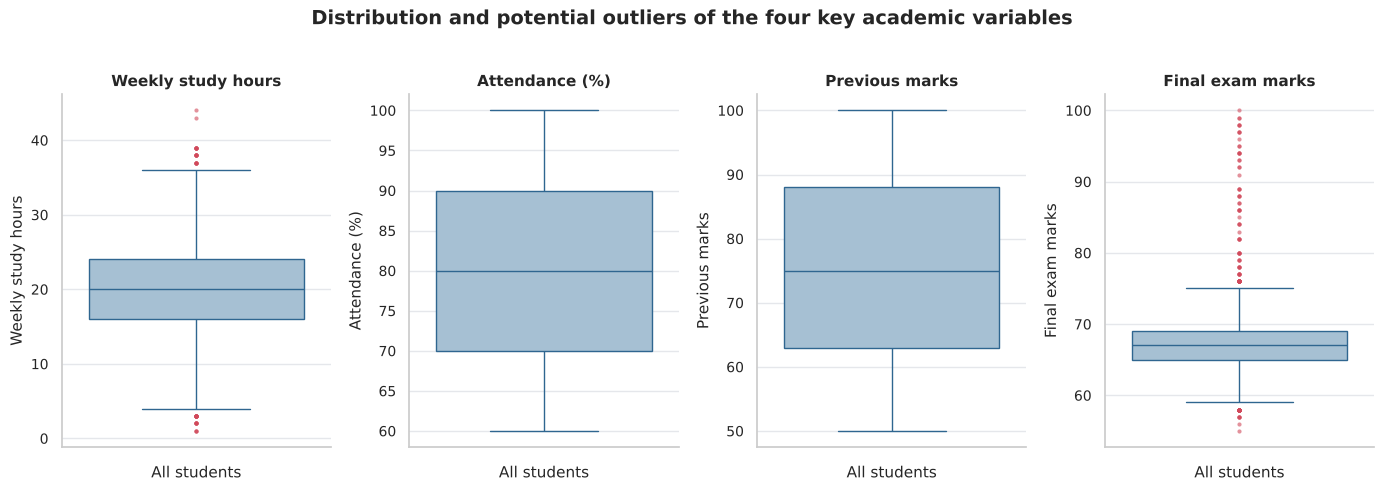

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.8))
specs = [("Hours_Studied", "Weekly study hours"), ("Attendance", "Attendance (%)"),
         ("Previous_Scores", "Previous marks"), ("Exam_Score", "Final exam marks")]
for ax, (column, label) in zip(axes, specs):
    sns.boxplot(y=df[column], ax=ax, color="#9ec1da", linecolor=BLUE, fliersize=3,
                flierprops={"markerfacecolor": ACCENT, "markeredgecolor": "none", "alpha": 0.6})
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("All students")
    ax.set_ylabel(label)
fig.suptitle("Distribution and potential outliers of the four key academic variables", fontsize=14, fontweight="bold", y=1.02)
save_and_show(fig, "13_box_key_variables.png")

**Interpretation - the four key variables.** *Study hours:* median 20, with a small number of dots above about 36 and below 4 hours (43 students, 0.65 %). *Attendance and previous marks:* the boxes fill most of the possible range and there are **no outliers at all** - values are evenly spread. *Final exam marks:* a very narrow box (65-69) with many dots mostly *above* the upper whisker (103 students, 1.56 %) - the high-scoring tail. This confirms that high final scores are the main source of unusual values in this dataset.

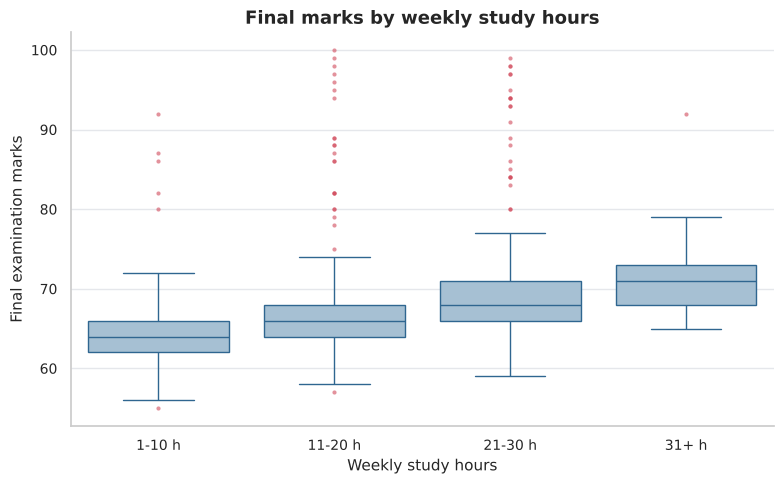

In [28]:
def box_score_by_band(band_column, xlabel, title, filename):
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(data=df, x=band_column, y="Exam_Score", ax=ax, color="#9ec1da", linecolor=BLUE, fliersize=3,
                flierprops={"markerfacecolor": ACCENT, "markeredgecolor": "none", "alpha": 0.6})
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Final examination marks")
    save_and_show(fig, filename)

box_score_by_band("Study_Hours_Band", "Weekly study hours", "Final marks by weekly study hours", "14_box_exam_by_study_hours.png")

**Interpretation.** The whole box moves upward from the 1-10 h group (median 64) to the 31+ h group (median 71), so the shift is not caused by a few extreme students - the **typical** student in each group differs. The spread (box height) is similar in every group. Unusual high scores (red dots) appear in all groups, including students who study little.

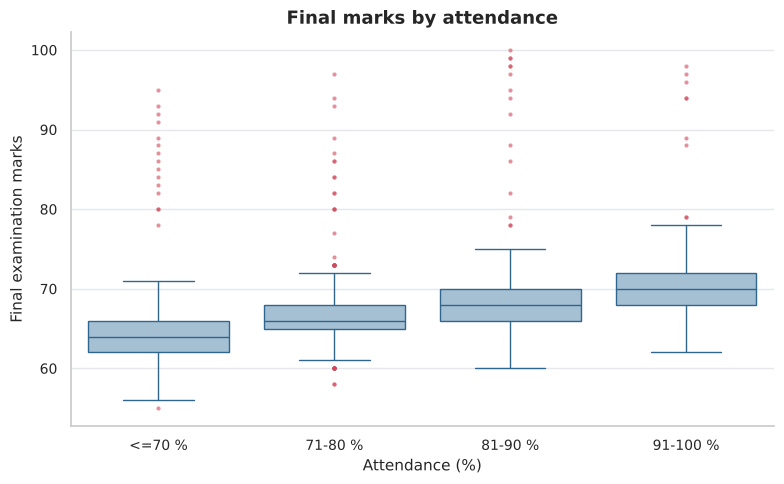

In [29]:
box_score_by_band("Attendance_Band", "Attendance (%)", "Final marks by attendance", "15_box_exam_by_attendance.png")

**Interpretation.** Median final marks climb from 64 (attendance <=70 %) to 70 (91-100 %), and the boxes barely overlap at the extremes: the middle half of the lowest-attendance group sits below the middle half of the highest-attendance group. The highest-attendance group also has the narrowest spread. Again, this is an association between attendance and marks, not proof of cause.

# 19. Correlation Heatmap

The heatmap shows Pearson's correlation (*r*, from -1 to +1) between every pair of numeric columns. The top row/column (`Exam_Score`) is the one to read for relationships with the final score.

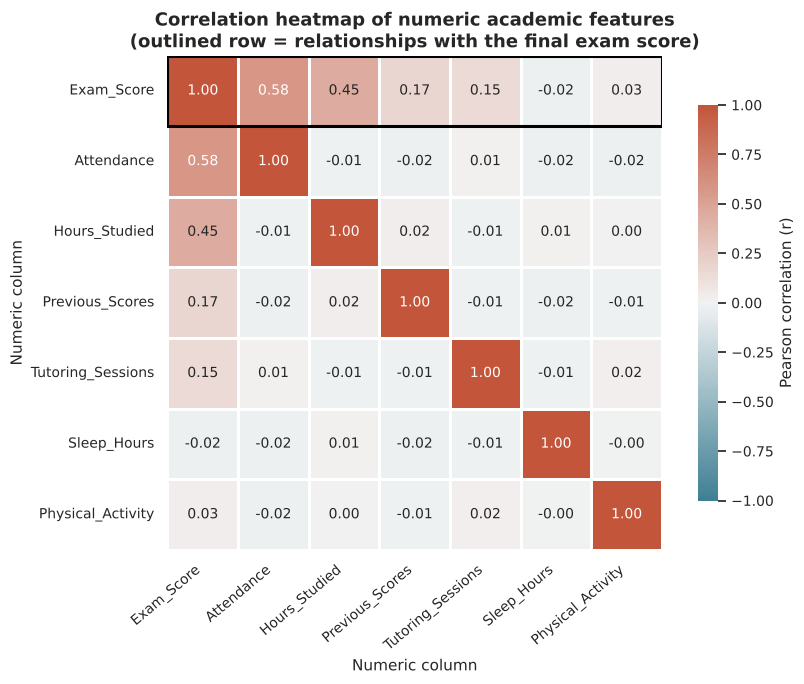

,Exam_Score,Attendance,Hours_Studied,Previous_Scores,Tutoring_Sessions,Sleep_Hours,Physical_Activity
Exam_Score,1.000,0.582,0.447,0.174,0.154,-0.016,0.028
Attendance,0.582,1.000,-0.010,-0.020,0.014,-0.016,-0.022
Hours_Studied,0.447,-0.010,1.000,0.025,-0.015,0.011,0.005
Previous_Scores,0.174,-0.020,0.025,1.000,-0.014,-0.022,-0.011
Tutoring_Sessions,0.154,0.014,-0.015,-0.014,1.000,-0.012,0.018
Sleep_Hours,-0.016,-0.016,0.011,-0.022,-0.012,1.000,-0.000
Physical_Activity,0.028,-0.022,0.005,-0.011,0.018,-0.000,1.000


In [30]:
heatmap_columns = ["Exam_Score", "Attendance", "Hours_Studied", "Previous_Scores", "Tutoring_Sessions", "Sleep_Hours", "Physical_Activity"]
corr_matrix = df[heatmap_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap=sns.diverging_palette(220, 20, as_cmap=True),
            vmin=-1, vmax=1, center=0, square=True, linewidths=1, linecolor="white",
            cbar_kws={"label": "Pearson correlation (r)", "shrink": 0.8}, annot_kws={"size": 10}, ax=ax)
ax.add_patch(plt.Rectangle((0, 0), 7, 1, fill=False, edgecolor="black", linewidth=2.2))   # highlight the Exam_Score row
ax.set_title("Correlation heatmap of numeric academic features\n(outlined row = relationships with the final exam score)")
ax.set_xlabel("Numeric column")
ax.set_ylabel("Numeric column")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
save_and_show(fig, "16_correlation_heatmap.png")
corr_matrix.round(3)

**Interpretation.** *What it shows:* all pairwise correlations. *Pattern in the outlined row:* `Exam_Score` correlates positively with `Attendance` (0.58) and `Hours_Studied` (0.45), weakly with `Previous_Scores` (0.17) and `Tutoring_Sessions` (0.15), and hardly at all with `Sleep_Hours` and `Physical_Activity`. *Pattern among the inputs:* the correlations between `Attendance`, `Hours_Studied` and `Previous_Scores` are all close to zero (between -0.02 and +0.03). *What this suggests:* the three chosen inputs carry **different, non-overlapping information** (little multicollinearity), which is ideal for Linear Regression because each coefficient can be interpreted separately. A heatmap shows only linear association between pairs; it cannot show causation.

# 20. EDA Findings and Interpretation

**Summary of what the exploration shows (statistical patterns in this dataset):**

1. **Attendance** has the strongest association with final marks (r = 0.58; roughly +0.2 marks per extra attendance point).
2. **Study hours** are also clearly associated with final marks (r = 0.45; roughly +0.29 marks per extra weekly hour).
3. **Previous marks** are only weakly associated with final marks (r = 0.17).
4. The three inputs are almost uncorrelated with each other, so each adds distinct information.
5. Final marks are tightly clustered (SD 3.9) with a small group of unusually high scores (about 1.6 % outliers), which makes high-end scores hard to predict.
6. Sleep and physical activity show essentially no linear association with final marks here.

**What EDA cannot tell us:** *why* these patterns exist. Students who attend more or study more may also be more motivated, better supported, or differ in other unmeasured ways. All statements above are **associations, not causal conclusions**.

# 21. Feature Selection

**Chosen input features (X):**

| Feature | Meaning | Why chosen |
|---|---|---|
| `Hours_Studied` | weekly study hours | required by the project; clear association with marks (r = 0.45) |
| `Attendance` | attendance percentage | required by the project; strongest association (r = 0.58) |
| `Previous_Scores` | previous examination marks | required by the project; weak but real association (r = 0.17) |

**Deliberately NOT used as inputs**

- `Score_Change`, `Performance_Level` - calculated from the target, so they would **leak the answer**.
- The three band columns - they are only coarser copies of the numeric columns.
- Other columns in the dataset (parental involvement, sleep, tutoring, ...) - the project brief asks for study hours, attendance and previous marks; the brief allows extra features only when appropriate, and keeping three inputs keeps the model simple and easy to explain. Using them is listed as a future improvement.

All three chosen features would realistically be known **before** the final exam, so the model does not use information from the future.

In [31]:
FEATURE_COLUMNS = ["Hours_Studied", "Attendance", "Previous_Scores"]
TARGET_COLUMN = "Exam_Score"

X = df[FEATURE_COLUMNS]
print("Input features (X):", FEATURE_COLUMNS)
print("X shape:", X.shape, "| missing values in X:", int(X.isna().sum().sum()))
X.head()

Input features (X): ['Hours_Studied', 'Attendance', 'Previous_Scores']
X shape: (6606, 3) | missing values in X: 0


,Hours_Studied,Attendance,Previous_Scores
0,23,84,73
1,19,64,59
2,24,98,91
3,29,89,98
4,19,92,65


# 22. Target Variable Selection

The **target (y)** is `Exam_Score` - the final examination marks (out of 100). It is a continuous number, so this is a **regression** problem.

In [32]:
y = df[TARGET_COLUMN]
print("Target (y):", TARGET_COLUMN)
print(y.describe().round(2).to_string())

Target (y): Exam_Score
count    6606.00
mean       67.23
std         3.87
min        55.00
25%        65.00
50%        67.00
75%        69.00
max       100.00


# 23. Training and Testing Split

We split the data **before fitting anything**: 80 % for training (the model learns from these) and 20 % for testing (kept unseen until the final evaluation). `random_state = 42` makes the split reproducible.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print(f"Training set: {X_train.shape[0]} students ({X_train.shape[0] / len(df):.0%})")
print(f"Testing set : {X_test.shape[0]} students ({X_test.shape[0] / len(df):.0%})")
print("\nSanity checks")
print("  No student appears in both sets:", set(X_train.index).isdisjoint(set(X_test.index)))
print("  Train + test rows = all rows    :", len(X_train) + len(X_test) == len(df))
print(f"  Mean final score  train = {y_train.mean():.2f}, test = {y_test.mean():.2f} (similar -> representative split)")

Training set: 5284 students (80%)
Testing set : 1322 students (20%)

Sanity checks
  No student appears in both sets: True
  Train + test rows = all rows    : True
  Mean final score  train = 67.26, test = 67.10 (similar -> representative split)


# 24. Linear Regression Model Development

**Linear Regression** predicts the target as a weighted sum of the inputs:

$$\widehat{\text{Exam\_Score}} = b_0 + b_1\cdot\text{Hours\_Studied} + b_2\cdot\text{Attendance} + b_3\cdot\text{Previous\_Scores}$$

The model finds the intercept $b_0$ and the coefficients $b_1, b_2, b_3$ that minimise the sum of squared differences between actual and predicted marks (*ordinary least squares*).

**Leakage-safe design using a scikit-learn `Pipeline`:**

1. `SimpleImputer(median)` - fills a missing numeric input, if any (there are none here; it is a safeguard for new data);
2. `StandardScaler` - puts the features on a common scale;
3. `LinearRegression`.

Scaling does not change Linear Regression's predictions, but it makes the coefficients comparable and demonstrates the correct way to handle preprocessing: **the whole pipeline is fitted on training data only.** When the pipeline later predicts the test data, the imputer and scaler only *apply* what they learned from the training data.

In [34]:
def build_pipeline(fit_intercept=True):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression(fit_intercept=fit_intercept)),
    ])

model = build_pipeline()
print(model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('regressor', LinearRegression())])


# 25. Model Training

`fit` is called **only on the training data**.

In [35]:
model.fit(X_train, y_train)

scaler = model.named_steps["scaler"]
regressor = model.named_steps["regressor"]

# Convert coefficients back to the original units (marks per hour, per attendance point, per mark)
coef_original = regressor.coef_ / scaler.scale_
intercept_original = float(regressor.intercept_ - np.sum(regressor.coef_ * scaler.mean_ / scaler.scale_))
coef_table = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Coefficient_original_units": coef_original,
    "Coefficient_standardised": regressor.coef_,
})
coef_table.to_csv(RESULTS_DIR / "coefficients.csv", index=False)

print("Model trained on", len(X_train), "students.")
print(f"\nLearned equation:\n  Exam_Score = {intercept_original:.2f} "
      f"+ {coef_original[0]:.4f} x Hours_Studied + {coef_original[1]:.4f} x Attendance + {coef_original[2]:.4f} x Previous_Scores")
coef_table.round(4)

Model trained on 5284 students.

Learned equation:
  Exam_Score = 42.03 + 0.2874 x Hours_Studied + 0.1990 x Attendance + 0.0475 x Previous_Scores


,Feature,Coefficient_original_units,Coefficient_standardised
0,Hours_Studied,0.2874,1.7152
1,Attendance,0.1990,2.2954
2,Previous_Scores,0.0475,0.6816


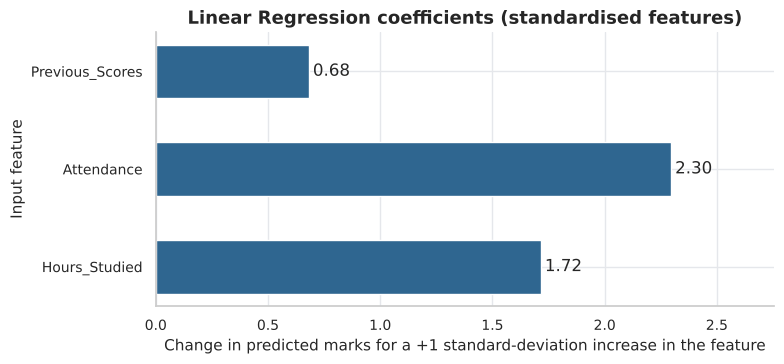

In [36]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(coef_table["Feature"], coef_table["Coefficient_standardised"], color=BLUE, height=0.55)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, coef_table["Coefficient_standardised"].max() * 1.2)
ax.set_title("Linear Regression coefficients (standardised features)")
ax.set_xlabel("Change in predicted marks for a +1 standard-deviation increase in the feature")
ax.set_ylabel("Input feature")
save_and_show(fig, "17_model_coefficients.png")

**Interpretation of the coefficients** (original units, holding the other two inputs fixed): each extra weekly study hour is associated with about **+0.29 marks**; each extra attendance percentage point with about **+0.20 marks**; each extra previous mark with only about **+0.05 marks**. The standardised bars show relative importance for *this model*: attendance (2.30) > study hours (1.72) > previous marks (0.68). These are associations learned from the data, not proof of cause and effect.

# 26. Predictions

Now the trained model predicts the final marks of the **unseen test students**. The test features were never used for fitting.

In [37]:
y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)
print("Predictions generated for", len(y_pred_test), "unseen test students.")
print("First 10 predicted marks:", np.round(y_pred_test[:10], 2))

Predictions generated for 1322 unseen test students.
First 10 predicted marks: [67.27 63.92 70.04 67.94 69.9  60.99 74.55 64.27 69.62 72.39]


# 27. Actual Versus Predicted Comparison

In [38]:
results = pd.DataFrame({"Actual": y_test.to_numpy(), "Predicted": y_pred_test}, index=y_test.index)
results["Error"] = results["Actual"] - results["Predicted"]          # positive = student scored higher than predicted
results["Absolute_Error"] = results["Error"].abs()

print("Actual vs predicted final marks - first 15 test students")
results.head(15).round(2)

Actual vs predicted final marks - first 15 test students


,Actual,Predicted,Error,Absolute_Error
6414,66,67.27,-1.27,1.27
6116,66,63.92,2.08,2.08
239,67,70.04,-3.04,3.04
1905,67,67.94,-0.94,0.94
6096,68,69.90,-1.90,1.90
6582,63,60.99,2.01,2.01
6131,74,74.55,-0.55,0.55
5176,65,64.27,0.73,0.73
2271,69,69.62,-0.62,0.62
2410,76,72.39,3.61,3.61


In [39]:
for tolerance in (2, 3, 5):
    share = (results["Absolute_Error"] <= tolerance).mean()
    print(f"Predictions within +/-{tolerance} marks of the actual score: {share:.1%}")
print(f"\nLargest single error: {results['Absolute_Error'].max():.1f} marks | median error: {results['Absolute_Error'].median():.2f} marks")

Predictions within +/-2 marks of the actual score: 79.8%
Predictions within +/-3 marks of the actual score: 94.4%
Predictions within +/-5 marks of the actual score: 99.4%

Largest single error: 30.5 marks | median error: 1.07 marks


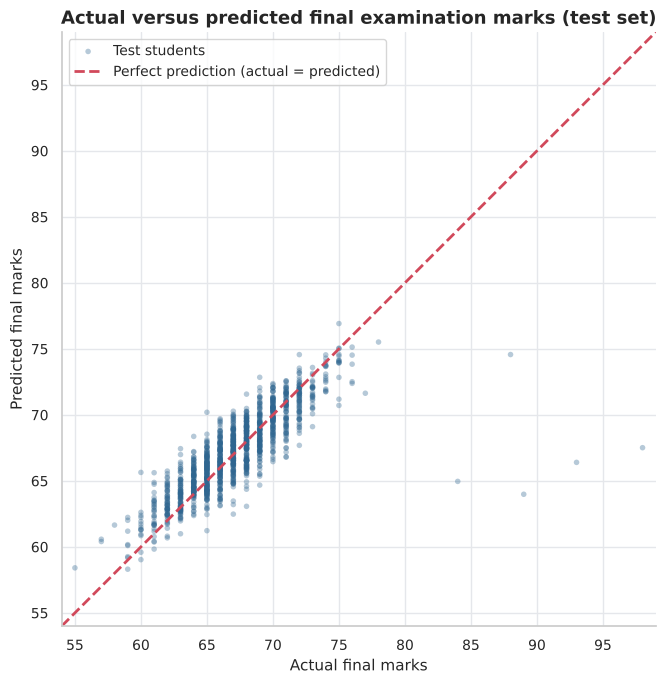

In [40]:
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(results["Actual"], results["Predicted"], s=16, alpha=0.35, color=BLUE, edgecolors="none", label="Test students")
low, high = results[["Actual", "Predicted"]].min().min() - 1, results[["Actual", "Predicted"]].max().max() + 1
ax.plot([low, high], [low, high], color=ACCENT, linewidth=2, linestyle="--", label="Perfect prediction (actual = predicted)")
ax.set_xlim(low, high); ax.set_ylim(low, high)
ax.set_aspect("equal")
ax.set_title("Actual versus predicted final examination marks (test set)")
ax.set_xlabel("Actual final marks")
ax.set_ylabel("Predicted final marks")
ax.legend(loc="upper left")
save_and_show(fig, "18_actual_vs_predicted.png")

**Interpretation.** *What it shows:* each dot is an unseen test student; a dot on the red dashed line would be a perfect prediction. *Pattern:* the dots follow the diagonal for the typical range (about 60-72 marks) but the predictions stay in a narrow band (roughly 60-76) while actual marks reach much higher; students with unusually high actual scores sit far *below* the line (under-predicted). *What it suggests:* the model captures the general level of a student well, but it cannot anticipate the unexplained high scores, which depend on factors not in the model. The compressed prediction range is typical of a model that explains only part of the variation.

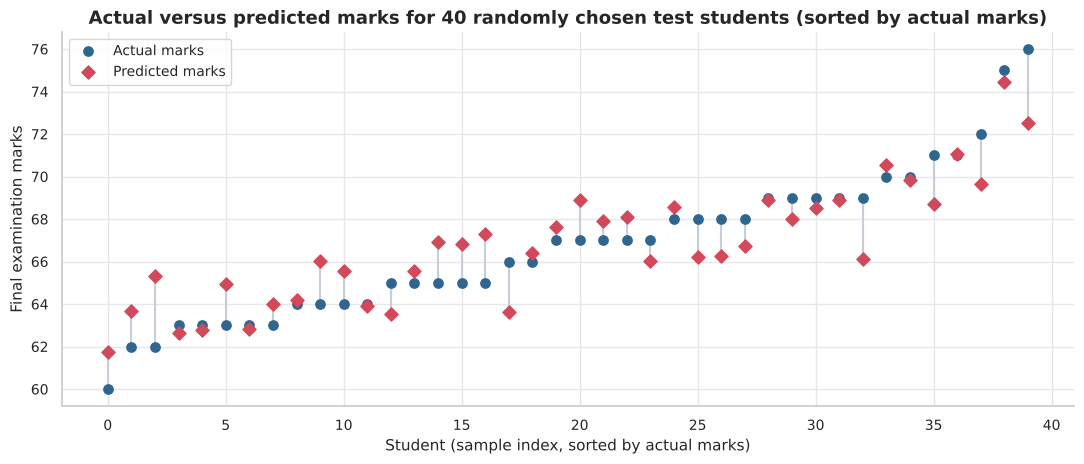

In [41]:
sample = results.sample(40, random_state=RANDOM_STATE).sort_values("Actual").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.vlines(sample.index, sample["Actual"], sample["Predicted"], color="#c7ced6", linewidth=1.5, zorder=1)
ax.scatter(sample.index, sample["Actual"], color=BLUE, s=45, zorder=2, label="Actual marks")
ax.scatter(sample.index, sample["Predicted"], color=ACCENT, s=45, marker="D", zorder=2, label="Predicted marks")
ax.set_title("Actual versus predicted marks for 40 randomly chosen test students (sorted by actual marks)")
ax.set_xlabel("Student (sample index, sorted by actual marks)")
ax.set_ylabel("Final examination marks")
ax.legend(loc="upper left")
save_and_show(fig, "19_actual_vs_predicted_sample.png")

**Interpretation.** The grey line joins each student's actual and predicted marks, so its length is the prediction error. For most of the 40 students the gap is only a mark or two; the longest gaps occur at the right-hand end, for students with the highest actual marks, whom the model under-predicts.

Mean residual = -0.099 marks (close to 0 -> no systematic over/under-prediction on average)
Residual skewness = 5.70 (positive -> a few large positive errors = under-predicted high scorers)


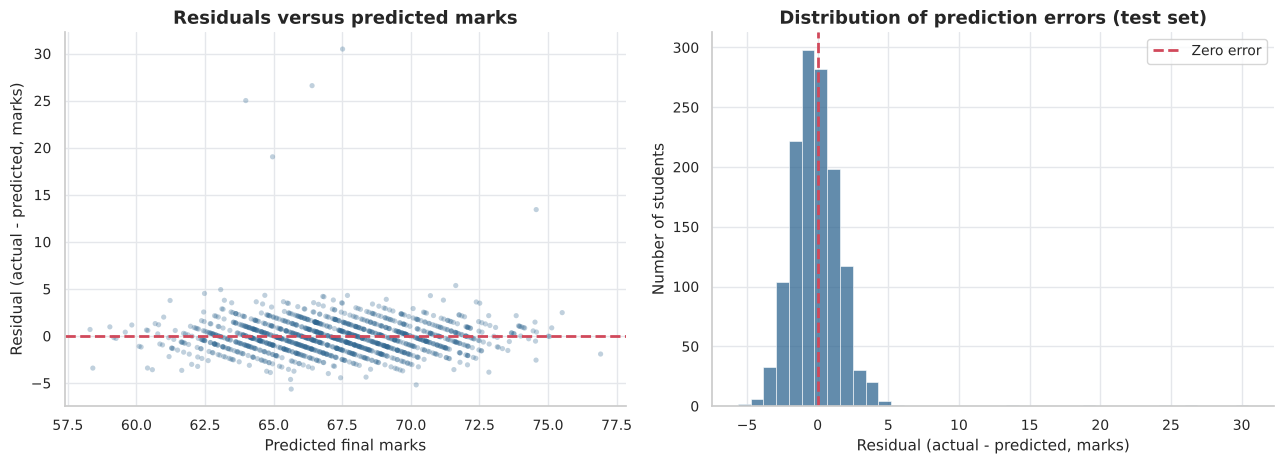

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(results["Predicted"], results["Error"], s=14, alpha=0.3, color=BLUE, edgecolors="none")
axes[0].axhline(0, color=ACCENT, linewidth=2, linestyle="--")
axes[0].set_title("Residuals versus predicted marks")
axes[0].set_xlabel("Predicted final marks")
axes[0].set_ylabel("Residual (actual - predicted, marks)")

sns.histplot(results["Error"], bins=40, color=BLUE, edgecolor="white", linewidth=0.4, ax=axes[1])
axes[1].axvline(0, color=ACCENT, linewidth=2, linestyle="--", label="Zero error")
axes[1].set_title("Distribution of prediction errors (test set)")
axes[1].set_xlabel("Residual (actual - predicted, marks)")
axes[1].set_ylabel("Number of students")
axes[1].legend()
save_and_show(fig, "20_residual_analysis.png")
print(f"Mean residual = {results['Error'].mean():.3f} marks (close to 0 -> no systematic over/under-prediction on average)")
print(f"Residual skewness = {results['Error'].skew():.2f} (positive -> a few large positive errors = under-predicted high scorers)")

**Interpretation of residuals.** The errors are centred on zero (mean about 0), so the model is not biased on average. The histogram is tall and narrow but has a **long right tail**: a few students scored far above their prediction. The left plot shows no curve or funnel pattern in the typical range, which supports using a straight-line model, while the stray points at the top are the unexplained high scorers.

# 28. Model Evaluation

We evaluate with three metrics from `sklearn.metrics`. To give the numbers context we also compute a **baseline**: always predicting the training-set average mark. A useful model must beat this.

In [43]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }

test_metrics = regression_metrics(y_test, y_pred_test)
train_metrics = regression_metrics(y_train, y_pred_train)
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_metrics = regression_metrics(y_test, baseline_pred)

evaluation_table = pd.DataFrame({
    "Linear Regression - TEST (unseen)": test_metrics,
    "Linear Regression - TRAIN": train_metrics,
    "Baseline (always predict train mean) - TEST": baseline_metrics,
}).T.round(4)
evaluation_table.index.name = "Model / data"
evaluation_table.to_csv(RESULTS_DIR / "model_evaluation_summary.csv")
evaluation_table

,MAE,RMSE,R2
Model / data,,,
Linear Regression - TEST (unseen),1.3296,2.1346,0.6554
Linear Regression - TRAIN,1.4401,2.6107,0.5572
Baseline (always predict train mean) - TEST,2.7629,3.6401,-0.0020


# 29. MAE (Mean Absolute Error)

**Meaning.** The average size of the prediction error, ignoring direction, in the same units as the target (marks). Lower is better. If MAE = 1.3, the model is on average 1.3 marks away from the true mark.

In [44]:
mae = mean_absolute_error(y_test, y_pred_test)
print(f"MAE (test set)     = {mae:.4f} marks")
print(f"MAE (baseline)     = {baseline_metrics['MAE']:.4f} marks")
print(f"Manual check       = {np.mean(np.abs(y_test.to_numpy() - y_pred_test)):.4f} marks (mean of |actual - predicted|)")
print(f"\nImprovement over baseline: {1 - mae / baseline_metrics['MAE']:.1%}")

MAE (test set)     = 1.3296 marks
MAE (baseline)     = 2.7629 marks
Manual check       = 1.3296 marks (mean of |actual - predicted|)

Improvement over baseline: 51.9%


**Interpretation.** On unseen students the model's typical prediction is about **1.33 marks** from the actual mark, compared with 2.76 marks for the "predict the average" baseline - an error reduction of about 52 %. Because final marks have a spread of only about 3.9 marks, an MAE of 1.3 marks is good in relative terms.

# 30. RMSE (Root Mean Squared Error)

**Meaning.** The square root of the average *squared* error. Like MAE it is in marks, but squaring makes **large errors count much more**. RMSE is always at least as large as MAE; a big gap between them means a few large errors exist.

In [45]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"RMSE (test set)    = {rmse:.4f} marks")
print(f"RMSE (baseline)    = {baseline_metrics['RMSE']:.4f} marks")
print(f"Manual check       = {np.sqrt(np.mean((y_test.to_numpy() - y_pred_test) ** 2)):.4f} marks")
print(f"RMSE / MAE ratio   = {rmse / mae:.2f}  (1.0 would mean all errors are the same size; larger -> a few big errors)")
squared_errors = np.sort((results['Error'] ** 2).to_numpy())[::-1]
top = int(np.ceil(0.01 * len(squared_errors)))
print(f"The largest {top} errors (1 % of students) make up {squared_errors[:top].sum() / squared_errors.sum():.0%} of the total squared error.")

RMSE (test set)    = 2.1346 marks
RMSE (baseline)    = 3.6401 marks
Manual check       = 2.1346 marks
RMSE / MAE ratio   = 1.61  (1.0 would mean all errors are the same size; larger -> a few big errors)
The largest 14 errors (1 % of students) make up 50% of the total squared error.


**Interpretation.** RMSE is about **2.13 marks** (baseline 3.64). It is larger than MAE (1.33) because of the few large errors on the unusually high scorers: the 1 % of test students with the biggest errors account for about half of all squared error. So typical predictions are better than RMSE suggests, while the occasional miss can be large.

# 31. R² Score (Coefficient of Determination)

**Meaning.** The proportion of the variation in final marks that the model explains. R² = 1 is perfect; R² = 0 is no better than always predicting the mean; negative means worse than the mean.

In [46]:
r2 = r2_score(y_test, y_pred_test)
manual_r2 = 1 - np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print(f"R² (test set)      = {r2:.4f}  -> the model explains {r2:.1%} of the variation in unseen students' marks")
print(f"Manual check       = {manual_r2:.4f}")
print(f"R² (training set)  = {train_metrics['R2']:.4f}")
print(f"R² (baseline)      = {baseline_metrics['R2']:.4f} (always about 0 by definition)")
big_train = int((np.abs(y_train - y_pred_train) > 8).sum())
big_test = int((np.abs(y_test - y_pred_test) > 8).sum())
print(f"\nStudents with an error above 8 marks: training {big_train} of {len(y_train)} ({big_train / len(y_train):.1%}), "
      f"test {big_test} of {len(y_test)} ({big_test / len(y_test):.1%})")

R² (test set)      = 0.6554  -> the model explains 65.5% of the variation in unseen students' marks
Manual check       = 0.6554
R² (training set)  = 0.5572
R² (baseline)      = -0.0020 (always about 0 by definition)

Students with an error above 8 marks: training 44 of 5284 (0.8%), test 5 of 1322 (0.4%)


**Interpretation.** On the test set, R² = **0.655**: the three inputs explain roughly two-thirds of the variation in final marks; one-third is due to other factors or randomness. The training R² (0.557) is *lower* than the test R² - unusual (normally training is higher). The reason is the high-scoring outliers: 44 of the 5,284 training students (0.8 %) have errors above 8 marks, against only 5 of 1,322 test students (0.4 %), so by chance the test set contains fewer extreme cases. This is **not a sign of leakage** (the test set was never used for fitting), but it means the test R² is probably slightly optimistic. Cross-validation (next section) gives a more cautious estimate.

# 32. Cross-Validation

A single train/test split can be lucky or unlucky. **5-fold cross-validation** splits the *training* data into 5 parts; the model is trained on 4 parts and validated on the 5th, five times. The test set is **not touched**. Because we pass the whole `Pipeline` to scikit-learn, the imputer and scaler are re-fitted inside every fold using that fold's training part only - no leakage.

In [47]:
cv_strategy = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_raw = cross_validate(
    build_pipeline(), X_train, y_train, cv=cv_strategy,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
)
cv_table = pd.DataFrame({
    "Fold": np.arange(1, CV_FOLDS + 1),
    "MAE": -cv_raw["test_MAE"],
    "RMSE": -cv_raw["test_RMSE"],
    "R2": cv_raw["test_R2"],
})
cv_table.to_csv(RESULTS_DIR / "cross_validation_results.csv", index=False)

cv_summary = pd.DataFrame({"Mean": cv_table[["MAE", "RMSE", "R2"]].mean(), "Std Dev": cv_table[["MAE", "RMSE", "R2"]].std(ddof=1)}).round(4)
print("Per-fold validation scores")
print(cv_table.round(4).to_string(index=False))
print("\nSummary over 5 folds")
print(cv_summary.to_string())

Per-fold validation scores
 Fold    MAE   RMSE     R2
    1 1.4009 2.4145 0.5916
    2 1.4861 2.9773 0.4923
    3 1.5274 2.9884 0.5033
    4 1.3647 2.2068 0.6312
    5 1.4283 2.3771 0.5974

Summary over 5 folds
        Mean  Std Dev
MAE   1.4415   0.0654
RMSE  2.5928   0.3646
R2    0.5632   0.0617


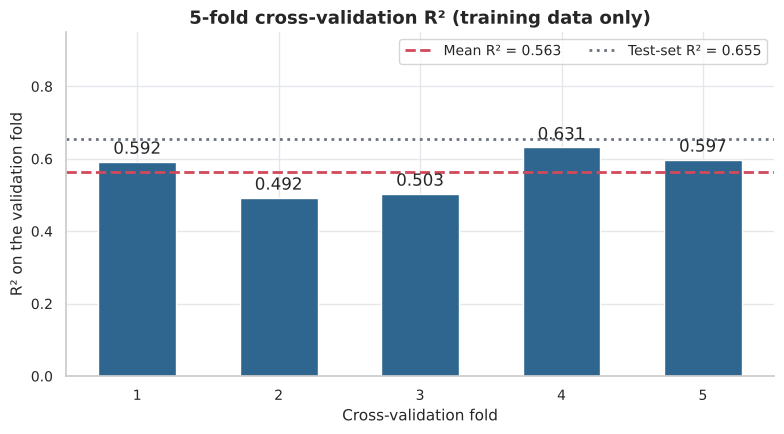

In [48]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(cv_table["Fold"].astype(str), cv_table["R2"], color=BLUE, width=0.55)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.axhline(cv_table["R2"].mean(), color=ACCENT, linestyle="--", linewidth=2, label=f"Mean R² = {cv_table['R2'].mean():.3f}")
ax.axhline(r2, color=GREY, linestyle=":", linewidth=2, label=f"Test-set R² = {r2:.3f}")
ax.set_ylim(0, 0.95)
ax.set_title("5-fold cross-validation R² (training data only)")
ax.set_xlabel("Cross-validation fold")
ax.set_ylabel("R² on the validation fold")
ax.legend(loc="upper right", ncol=2)
save_and_show(fig, "21_cross_validation_r2.png")

**Interpretation.** Cross-validated R² averages **0.563** (standard deviation 0.062; folds range from 0.49 to 0.63), the mean CV MAE is 1.44 and the mean CV RMSE is 2.59. The folds vary noticeably because a few high-scoring outliers land in different folds. The test-set R² (0.655) is higher than the CV mean and even higher than the best single fold (0.631), which reinforces the point from Section 31: the test split happened to contain fewer extreme cases. A fair summary is that the model explains **roughly 55-65 % of the variation** in unseen students' marks, with typical errors of about 1.3-1.5 marks.

# 33. Hyperparameter Tuning Discussion

Standard (ordinary least squares) `LinearRegression` has **no meaningful hyperparameters to tune**: its coefficients are computed directly from the data in a single step. The only constructor option of practical relevance is `fit_intercept` (whether to learn the constant term $b_0$). We do not invent tuning parameters; instead we run an honest `GridSearchCV` on the *training data only* to confirm that keeping the intercept is the right choice.

In [49]:
grid = GridSearchCV(
    build_pipeline(), param_grid={"regressor__fit_intercept": [True, False]},
    cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
)
grid.fit(X_train, y_train)               # training data only - the test set is never used for tuning

tuning_table = pd.DataFrame({
    "fit_intercept": grid.cv_results_["param_regressor__fit_intercept"].astype(bool),
    "mean_cv_RMSE": -grid.cv_results_["mean_test_score"],
})
tuning_table.to_csv(RESULTS_DIR / "fit_intercept_check.csv", index=False)
print("Best setting found:", grid.best_params_)
tuning_table.round(4)

Best setting found: {'regressor__fit_intercept': True}


,fit_intercept,mean_cv_RMSE
0,True,2.5928
1,False,67.3138


**Interpretation.** With the intercept the cross-validated RMSE is 2.59 marks; without it, it is 67.3 marks - an absurd error, because the average mark is about 67 and a model forced through the origin cannot represent that baseline. `fit_intercept=True` (the default) is clearly correct, so the model is unchanged. This is a sanity check, **not a performance-improving tuning exercise**. Regularised variants (Ridge/Lasso) do have a tuning parameter, but they were not requested and the three inputs are nearly uncorrelated, so regularisation would be expected to help little; they are mentioned under future improvements.

# 34. Data Leakage Prevention

*Data leakage* happens when information from the test data (or from the answer) influences training, producing results that look better than they really are. The checks below verify each safeguard programmatically.

In [50]:
checks = {}

# 1. Split happened before any fitting; no student in both sets
checks["Train/test students are disjoint"] = set(X_train.index).isdisjoint(X_test.index)

# 2. The fitted scaler learned its statistics from TRAINING data only
checks["Scaler mean equals the TRAIN mean"] = bool(np.allclose(scaler.mean_, X_train.mean().to_numpy()))
checks["Scaler mean differs from the FULL-data mean (so the test set was not used)"] = not np.allclose(scaler.mean_, X.mean().to_numpy(), atol=1e-12)

# 3. No target-derived column among the inputs, and the target is not an input
checks["Target not in inputs"] = TARGET_COLUMN not in FEATURE_COLUMNS
checks["No target-derived columns in inputs"] = not ({"Score_Change", "Performance_Level"} & set(FEATURE_COLUMNS))

# 4. Cross-validation folds are built from the training data only: no test student is in any fold
checks["No test student appears in any cross-validation fold"] = all(
    set(X_train.index[validation_idx]).isdisjoint(X_test.index) and set(X_train.index[training_idx]).isdisjoint(X_test.index)
    for training_idx, validation_idx in cv_strategy.split(X_train)
)

# 5. Preprocessing lives inside the Pipeline (refitted per CV fold)
checks["Preprocessing is inside the Pipeline"] = [name for name, _ in model.steps] == ["imputer", "scaler", "regressor"]

for description, passed in checks.items():
    print(("PASS  " if passed else "FAIL  ") + description)
assert all(checks.values()), "A leakage check failed!"
print("\nDesign note (cannot be tested by code): the three inputs - study hours, attendance, previous marks - "
      "are all known before the final exam.")
print("\nScaler mean (train)    :", np.round(scaler.mean_, 4))
print("Mean of full data      :", np.round(X.mean().to_numpy(), 4))

PASS  Train/test students are disjoint
PASS  Scaler mean equals the TRAIN mean
PASS  Scaler mean differs from the FULL-data mean (so the test set was not used)
PASS  Target not in inputs
PASS  No target-derived columns in inputs
PASS  No test student appears in any cross-validation fold
PASS  Preprocessing is inside the Pipeline

Design note (cannot be tested by code): the three inputs - study hours, attendance, previous marks - are all known before the final exam.

Scaler mean (train)    : [20.0091 79.9951 75.0343]
Mean of full data      : [19.9743 79.9747 75.0678]


**Result.** All checks pass. In summary: (1) the data were split first; (2) imputer, scaler and model were fitted on training data only and merely *applied* to the test data; (3) cross-validation re-fitted the entire pipeline inside each fold of the training data; (4) hyperparameter checking used the training data only; (5) the test set was used exactly once, for the final evaluation; (6) target-derived columns (`Score_Change`, `Performance_Level`) were excluded. Therefore the reported test metrics reflect genuine performance on unseen data. (Sections 32-33 call `cross_validate` / `GridSearchCV` with `X_train` and `y_train` only, and the check above confirms that no test student is inside any fold.)

# 35. Prediction Function

`predict_final_marks()` lets anyone estimate a student's final marks from three inputs. It **validates the inputs** and refuses impossible values instead of silently accepting them:

- study hours must be a finite number from 0 to 168 (hours in a week) - negative values are rejected;
- attendance must be between 0 and 100 %;
- previous marks must be between 0 and 100;
- text, booleans, `NaN` and infinity are rejected;
- valid inputs that lie *outside the range seen in training* produce a warning (a straight-line model extrapolates less reliably there);
- the prediction is limited to 0-100 because marks cannot be outside that range.

In [51]:
MARKS_RANGE = (0.0, 100.0)
ATTENDANCE_RANGE = (0.0, 100.0)
MAX_STUDY_HOURS_PER_WEEK = 168.0
training_ranges = X_train.agg(["min", "max"])        # used only to warn about extrapolation


def _validate_number(value, name, low, high, unit):
    if isinstance(value, bool) or not isinstance(value, (int, float, np.integer, np.floating)):
        raise TypeError(f"{name} must be a number, got {type(value).__name__}.")
    value = float(value)
    if not np.isfinite(value):
        raise ValueError(f"{name} must be a finite number, got {value}.")
    if value < low or value > high:
        raise ValueError(f"{name} must be between {low:g} and {high:g} {unit}; got {value:g}.")
    return value


def predict_final_marks(study_hours, attendance_percentage, previous_exam_marks, fitted_model=model):
    # Predict final examination marks (out of 100) for one student.
    hours = _validate_number(study_hours, "study_hours", 0.0, MAX_STUDY_HOURS_PER_WEEK, "hours per week")
    attendance = _validate_number(attendance_percentage, "attendance_percentage", *ATTENDANCE_RANGE, "percent")
    previous = _validate_number(previous_exam_marks, "previous_exam_marks", *MARKS_RANGE, "marks")

    new_student = pd.DataFrame([[hours, attendance, previous]], columns=FEATURE_COLUMNS)
    for column in FEATURE_COLUMNS:
        low, high = training_ranges.loc["min", column], training_ranges.loc["max", column]
        if not (low <= new_student.loc[0, column] <= high):
            warnings.warn(f"{column}={new_student.loc[0, column]:g} is outside the range seen in training "
                          f"({low:g} to {high:g}); the prediction is an extrapolation.", UserWarning, stacklevel=2)
    return float(np.clip(fitted_model.predict(new_student)[0], *MARKS_RANGE))


print("predict_final_marks defined.")

predict_final_marks defined.


In [52]:
# Valid examples
examples = [(10, 60, 50), (20, 80, 75), (22, 85, 70), (30, 95, 90), (35, 100, 100)]
example_rows = [{"Study_Hours": h, "Attendance_%": a, "Previous_Marks": p,
                 "Predicted_Final_Marks": round(predict_final_marks(h, a, p), 2)} for h, a, p in examples]
example_table = pd.DataFrame(example_rows)
example_table.to_csv(RESULTS_DIR / "prediction_function_examples.csv", index=False)
example_table

,Study_Hours,Attendance_%,Previous_Marks,Predicted_Final_Marks
0,10,60,50,59.22
1,20,80,75,67.26
2,22,85,70,68.59
3,30,95,90,73.83
4,35,100,100,76.74


In [53]:
# Invalid inputs must be rejected with a clear message (never silently accepted)
invalid_cases = [
    ("negative study hours", (-3, 80, 70)),
    ("more hours than exist in a week", (200, 80, 70)),
    ("attendance above 100 %", (20, 120, 70)),
    ("negative attendance", (20, -5, 70)),
    ("previous marks above 100", (20, 80, 150)),
    ("previous marks negative", (20, 80, -1)),
    ("not-a-number (NaN)", (float("nan"), 80, 70)),
    ("text instead of a number", ("twenty", 80, 70)),
    ("boolean instead of a number", (True, 80, 70)),
]
for label, arguments in invalid_cases:
    try:
        predict_final_marks(*arguments)
        print(f"NOT REJECTED (bug!): {label}")
    except (TypeError, ValueError) as error:
        print(f"Rejected  [{label}] -> {type(error).__name__}: {error}")

# Valid but unusual input: allowed, with a warning
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    value = predict_final_marks(100, 80, 70)
print(f"\nValid but outside training range (100 study hours/week): prediction = {value:.2f}; warning: {caught[0].message}")

Rejected  [negative study hours] -> ValueError: study_hours must be between 0 and 168 hours per week; got -3.
Rejected  [more hours than exist in a week] -> ValueError: study_hours must be between 0 and 168 hours per week; got 200.
Rejected  [attendance above 100 %] -> ValueError: attendance_percentage must be between 0 and 100 percent; got 120.
Rejected  [negative attendance] -> ValueError: attendance_percentage must be between 0 and 100 percent; got -5.
Rejected  [previous marks above 100] -> ValueError: previous_exam_marks must be between 0 and 100 marks; got 150.
Rejected  [previous marks negative] -> ValueError: previous_exam_marks must be between 0 and 100 marks; got -1.
Rejected  [not-a-number (NaN)] -> ValueError: study_hours must be a finite number, got nan.
Rejected  [text instead of a number] -> TypeError: study_hours must be a number, got str.
Rejected  [boolean instead of a number] -> TypeError: study_hours must be a number, got bool.

Valid but outside training range (100

**Reading the examples.** A student studying 10 h/week with 60 % attendance and 50 previous marks is predicted to score about 59; one with 20 h, 80 % and 75 marks about 67; one with 30 h, 95 % and 90 marks about 74. The predictions increase sensibly with each input. As the metrics show, each individual estimate typically carries an error of about 1-3 marks, so it should be read as an *expected value*, not a guarantee.

In [54]:
# Cross-check: the project's supporting module src/model.py must give the same results as this notebook
import importlib.util
module_path = PROJECT_ROOT / "src" / "model.py"
if module_path.exists():
    spec = importlib.util.spec_from_file_location("project_model", module_path)
    project_model = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(project_model)
    module_artefacts = project_model.train_and_evaluate(DATA_PATH)
    same_split = module_artefacts["X_test"].index.equals(X_test.index)
    same_metrics = all(np.isclose(module_artefacts["test_metrics"][k], test_metrics[k]) for k in test_metrics)
    same_prediction = np.isclose(project_model.predict_final_marks(22, 85, 70, module_artefacts["pipeline"],
                                 module_artefacts["X_train"].agg(["min", "max"])), predict_final_marks(22, 85, 70))
    print("src/model.py gives the same test split       :", same_split)
    print("src/model.py gives the same MAE/RMSE/R2      :", same_metrics)
    print("src/model.py gives the same example prediction:", bool(same_prediction))
else:
    print("src/model.py not found - cross-check skipped (the notebook is self-contained).")

src/model.py gives the same test split       : True
src/model.py gives the same MAE/RMSE/R2      : True
src/model.py gives the same example prediction: True


# 36. Results Interpretation

## Students who may benefit from additional academic support

We use two transparent indicators on the **test students** (computed from the model, not from personal labels):

1. **Predicted-low band** - the model predicts a final mark in the lowest quarter of the *training* marks (a mark of 65 or below). This can be used *before* an exam to prompt a supportive check-in.
2. **Below expectation** - the actual mark is more than one RMSE (about 2.1 marks) *below* what the model predicted. This is useful *after* an exam.

**These are prompts for a supportive conversation, not labels.** The model is imperfect (R² = 0.66), the indicators can be wrong for any individual, and they say nothing about the reasons for a result. No student should be judged, ranked or treated differently *solely* on this output.

In [55]:
support = results.copy()
low_threshold = float(y_train.quantile(0.25))
support["Predicted_Low_Band"] = support["Predicted"] <= low_threshold
support["Below_Expectation"] = (support["Predicted"] - support["Actual"]) > test_metrics["RMSE"]
support = support.join(X_test)

print(f"Predicted-low threshold (25th percentile of TRAINING marks): {low_threshold:.1f}")
print(f"Test students with predicted mark <= {low_threshold:.0f}      : {int(support['Predicted_Low_Band'].sum())} of {len(support)}")
print(f"Test students more than 1 RMSE below expectation : {int(support['Below_Expectation'].sum())} of {len(support)}")
print(f"Students flagged by both indicators              : {int((support['Predicted_Low_Band'] & support['Below_Expectation']).sum())}")

print("\nAverage inputs of the two groups (statistical pattern, not a verdict on any student):")
profile = support.groupby("Predicted_Low_Band")[FEATURE_COLUMNS].mean().round(1)
profile.index = ["Not in predicted-low band", "In predicted-low band"]
print(profile.to_string())

Predicted-low threshold (25th percentile of TRAINING marks): 65.0
Test students with predicted mark <= 65      : 331 of 1322
Test students more than 1 RMSE below expectation : 126 of 1322
Students flagged by both indicators              : 31

Average inputs of the two groups (statistical pattern, not a verdict on any student):
                           Hours_Studied  Attendance  Previous_Scores
Not in predicted-low band           21.2        83.8             76.7
In predicted-low band               15.7        68.3             70.6


In [56]:
review_columns = ["Hours_Studied", "Attendance", "Previous_Scores", "Actual", "Predicted", "Predicted_Low_Band", "Below_Expectation"]
review_candidates = support[support["Predicted_Low_Band"] | support["Below_Expectation"]][review_columns].round(1)
review_candidates = review_candidates.rename_axis("Original_Row_Index").reset_index()
review_candidates.to_csv(RESULTS_DIR / "support_review_candidates.csv", index=False)
print(f"{len(review_candidates)} test students are saved in outputs/evaluation_results/support_review_candidates.csv (row numbers only, no names).")
print("\nExample: the 8 lowest predicted marks")
review_candidates.sort_values("Predicted").head(8)

426 test students are saved in outputs/evaluation_results/support_review_candidates.csv (row numbers only, no names).

Example: the 8 lowest predicted marks


,Original_Row_Index,Hours_Studied,Attendance,Previous_Scores,Actual,Predicted,Predicted_Low_Band,Below_Expectation
152,6517,4,61,63,59,58.3,True,False
159,1101,3,62,67,55,58.4,True,True
147,79,8,61,54,60,59.0,True,False
254,4412,5,62,71,59,59.2,True,False
393,3518,7,60,69,59,59.3,True,False
118,5900,5,61,84,60,59.6,True,False
136,5805,6,66,62,61,59.8,True,False
369,2880,7,64,70,59,60.1,True,False


**Pattern in the flagged group.** Students in the predicted-low band have, on average, fewer study hours (15.7 h versus 21.2 h) and lower attendance (68.3 % versus 83.8 %) than the rest - exactly what the regression equation implies - and somewhat lower previous marks (70.6 versus 76.7). This tells us *where support conversations might be worth starting* (low attendance and low study time are the most visible signals) but it does not tell us *why* those students attend or study less.

## Answers to the key questions

1. **How accurately does the model predict marks?** On 1,322 unseen students: MAE 1.33 marks, RMSE 2.13 marks, R² 0.655. About 80 % of predictions are within 2 marks and 94 % within 3 marks. Cross-validation gives a slightly more cautious R² of 0.56 ± 0.06.
2. **Which features have meaningful relationships with final scores?** Attendance (r = 0.58) and study hours (r = 0.45) are the strongest; previous marks are weak (r = 0.17).
3. **Do study hours relate to performance?** Yes - positively. Each extra weekly hour is associated with about +0.29 marks (simple fit and model), and the 31+ h group averages about 7 marks more than the 1-10 h group.
4. **Does attendance relate to performance?** Yes - the strongest relationship. About +0.20 marks per attendance point; the 91-100 % group averages about 5.8 marks more than the <=70 % group.
5. **Do previous marks help explain final scores?** Only slightly: about +0.05 marks per previous mark, and 3 % of the variance on their own. They add a small but real contribution after attendance and study hours.
6. **What do the metrics indicate?** The model is clearly better than the "predict the average" baseline (RMSE 2.13 vs 3.64), explains roughly 55-65 % of the variation, and its typical error (about 1.3 marks) is small compared with the scores' spread. Large misses are concentrated in a few unusually high scorers.
7. **What limitations affect the predictions?** See the next section.

**Association is not causation.** None of these results shows that raising attendance or study hours *would cause* a student's marks to rise by the stated amounts.

# 37. Limitations

- **Dataset provenance.** The publisher does not document how the data were collected; the numeric columns are unusually regular (Section 14). Results describe this dataset and may not transfer to a real class or institution.
- **Narrow range of values.** Attendance is between 60 and 100 % and study hours between 1 and 44 per week; the model should not be trusted outside these ranges (the prediction function warns about this).
- **Unexplained variation.** About one-third of the variation in final marks is not explained by the three inputs; the model cannot foresee unusually high scorers (they are under-predicted).
- **Linear assumption.** Linear Regression assumes straight-line relationships and constant effects; possible curved or interaction effects are not modelled.
- **Association, not causation.** The data are observational. Hidden factors (motivation, support, prior ability) can drive both inputs and marks.
- **Self-reported or approximate inputs.** Study hours and attendance may be measured imprecisely.
- **One dataset, one split.** Test and cross-validation results differ by several R² points because a few extreme scores fall unevenly across splits.
- **Support indicators are crude.** They rely on one model with moderate accuracy and must never be used to label individuals.

# 38. Future Improvements

- Add further columns (for example tutoring sessions, parental involvement, motivation) and test whether they raise accuracy, using one-hot encoding inside the same Pipeline.
- Try Ridge/Lasso regression (with tuning of the regularisation strength) and non-linear models such as Random Forest or Gradient Boosting, comparing them with this Linear Regression baseline.
- Add the optional pass/fail **classification** model (Accuracy, Precision, Recall, F1-score) for early-warning support.
- Validate the approach on real, documented institutional data and repeat cross-validation several times for more stable estimates.
- Examine interaction terms (for example study hours × attendance) and prediction intervals to express uncertainty.
- Wrap `predict_final_marks()` in a small web or Streamlit form for teachers.

# 39. Conclusion

A complete Linear Regression workflow was built and evaluated on 6,606 cleaned student records (one impossible row removed, 235 missing category cells labelled "Unknown", no duplicates). Using only **study hours, attendance and previous marks**, the model predicts final examination marks on unseen students with **MAE 1.33, RMSE 2.13 and R² 0.655** (5-fold cross-validated R² 0.56 ± 0.06), clearly beating a predict-the-average baseline. **Attendance** and **study hours** show the strongest associations with final marks; **previous marks** show a weak one. All preprocessing was fitted on training data only, and leakage checks pass.

The findings are statistical patterns in a public dataset of undocumented origin; they do not prove cause and effect, and the model's flags for "additional support" are only prompts for a supportive conversation. The notebook, `src/model.py`, the charts, the evaluation files and the PDF report are all produced from the same code and the same results.

In [57]:
# Save the final metrics (same structure as src/model.py) and the test-set predictions
metrics_payload = {
    "test_set": test_metrics,
    "training_set": train_metrics,
    "baseline_test_set": baseline_metrics,
    "cross_validation_mean": {m: float(cv_table[m].mean()) for m in ["MAE", "RMSE", "R2"]},
    "cross_validation_std": {m: float(cv_table[m].std(ddof=1)) for m in ["MAE", "RMSE", "R2"]},
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "cv_folds": CV_FOLDS,
    "features": FEATURE_COLUMNS,
    "target": TARGET_COLUMN,
    "intercept_original_units": intercept_original,
    "share_within_2_marks": float((results["Absolute_Error"] <= 2).mean()),
    "share_within_3_marks": float((results["Absolute_Error"] <= 3).mean()),
    "share_within_5_marks": float((results["Absolute_Error"] <= 5).mean()),
    "support_predicted_low_threshold": low_threshold,
    "support_predicted_low_count": int(support["Predicted_Low_Band"].sum()),
    "support_below_expectation_count": int(support["Below_Expectation"].sum()),
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics_payload, indent=2))
results.rename_axis("Original_Row_Index").reset_index().to_csv(RESULTS_DIR / "predictions_test_set.csv", index=False)

print("Files saved in outputs/visualizations:")
for path in sorted(VIZ_DIR.glob("*.png")):
    print("  ", path.name)
print("\nFiles saved in outputs/evaluation_results:")
for path in sorted(RESULTS_DIR.glob("*")):
    print("  ", path.name)

Files saved in outputs/visualizations:
   01_missing_values_before_cleaning.png
   02_bar_mean_score_by_study_hours.png
   03_bar_mean_score_by_attendance.png
   04_bar_mean_score_by_previous_scores.png
   05_bar_correlation_with_exam_score.png
   06_hist_study_hours.png
   07_hist_attendance.png
   08_hist_previous_scores.png
   09_hist_exam_scores.png
   10_scatter_study_hours_vs_exam.png
   11_scatter_attendance_vs_exam.png
   12_scatter_previous_vs_exam.png
   13_box_key_variables.png
   14_box_exam_by_study_hours.png
   15_box_exam_by_attendance.png
   16_correlation_heatmap.png
   17_model_coefficients.png
   18_actual_vs_predicted.png
   19_actual_vs_predicted_sample.png
   20_residual_analysis.png
   21_cross_validation_r2.png

Files saved in outputs/evaluation_results:
   coefficients.csv
   cross_validation_results.csv
   data_cleaning_report.json
   descriptive_statistics.csv
   fit_intercept_check.csv
   metrics.json
   model_evaluation_summary.csv
   outlier_summary.csv
  